In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
import warnings

In [2]:
df = pd.read_csv("loan_data.csv")
df.head()

,person_age,person_gender,person_education,person_income,person_emp_exp,person_home_ownership,loan_amnt,loan_intent,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,credit_score,previous_loan_defaults_on_file,loan_status
0,22.0,female,Master,71948.0,0,RENT,35000.0,PERSONAL,16.02,0.49,3.0,561,No,1
1,21.0,female,High School,12282.0,0,OWN,1000.0,EDUCATION,11.14,0.08,2.0,504,Yes,0
2,25.0,female,High School,12438.0,3,MORTGAGE,5500.0,MEDICAL,12.87,0.44,3.0,635,No,1
3,23.0,female,Bachelor,79753.0,0,RENT,35000.0,MEDICAL,15.23,0.44,2.0,675,No,1
4,24.0,male,Master,66135.0,1,RENT,35000.0,MEDICAL,14.27,0.53,4.0,586,No,1


# **Null Value Check**

In [3]:
# prompt: Check for null values in the dataset

# Check for null values in each column
print(df.isnull().sum())


person_age                        0
person_gender                     0
person_education                  0
person_income                     0
person_emp_exp                    0
person_home_ownership             0
loan_amnt                         0
loan_intent                       0
loan_int_rate                     0
loan_percent_income               0
cb_person_cred_hist_length        0
credit_score                      0
previous_loan_defaults_on_file    0
loan_status                       0
dtype: int64


In [4]:
# Show each feature type
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45000 entries, 0 to 44999
Data columns (total 14 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   person_age                      45000 non-null  float64
 1   person_gender                   45000 non-null  object 
 2   person_education                45000 non-null  object 
 3   person_income                   45000 non-null  float64
 4   person_emp_exp                  45000 non-null  int64  
 5   person_home_ownership           45000 non-null  object 
 6   loan_amnt                       45000 non-null  float64
 7   loan_intent                     45000 non-null  object 
 8   loan_int_rate                   45000 non-null  float64
 9   loan_percent_income             45000 non-null  float64
 10  cb_person_cred_hist_length      45000 non-null  float64
 11  credit_score                    45000 non-null  int64  
 12  previous_loan_defaults_on_file  

# **Check Duplicate Row**

In [5]:
# prompt: Check if there is any duplicate instance in the df

# Check for duplicate rows
duplicates = df.duplicated().sum()

if duplicates > 0:
  print(f"There are {duplicates} duplicate rows in the DataFrame.")
  print("Here are the duplicate rows:")
  display(df[df.duplicated(keep=False)])
else:
  print("There are no duplicate rows in the DataFrame.")

There are no duplicate rows in the DataFrame.


In [6]:
# Remove duplicate rows
df_before_drop = df.shape[0]
df.drop_duplicates(inplace=True)
df_after_drop = df.shape[0]

print(f"Number of rows before dropping duplicates: {df_before_drop}")
print(f"Number of rows after dropping duplicates: {df_after_drop}")
print(f"Number of duplicate rows dropped: {df_before_drop - df_after_drop}")

Number of rows before dropping duplicates: 45000
Number of rows after dropping duplicates: 45000
Number of duplicate rows dropped: 0


In [7]:
from google.colab import files

# Define the filename for the new CSV
output_filename = "loan_data_no_duplicates.csv"

# Save the DataFrame to a CSV file
df.to_csv(output_filename, index=False)

# Download the file
files.download(output_filename)
print(f"'{output_filename}' has been downloaded.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

'loan_data_no_duplicates.csv' has been downloaded.


# **Applying MinaxScaler**

In [8]:
# Step 1: Import necessary libraries
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
from google.colab import files

# Step 2: Load the dataset
df = pd.read_csv("loan_data_no_duplicates.csv")

# Step 3: Identify all numerical (float/int) columns
numerical_cols = df.select_dtypes(include=['float64', 'int64']).columns

# Step 4: Apply MinMax Scaling
scaler = MinMaxScaler()
df[numerical_cols] = scaler.fit_transform(df[numerical_cols])

# Step 5: Show scaled values (first 5 rows)
print("Scaled Numerical Columns (first 5 rows):")
print(df[numerical_cols].head())

# Step 6: Save to CSV
scaled_filename = "loan_data_MinMax.csv"
df.to_csv(scaled_filename, index=False)

# Step 7: Download the CSV
files.download(scaled_filename)


Scaled Numerical Columns (first 5 rows):
   person_age  person_income  person_emp_exp  loan_amnt  loan_int_rate  \
0    0.016129       0.008891           0.000   1.000000       0.727023   
1    0.008065       0.000595           0.000   0.014493       0.392318   
2    0.040323       0.000617           0.024   0.144928       0.510974   
3    0.024194       0.009976           0.000   1.000000       0.672840   
4    0.032258       0.008082           0.008   1.000000       0.606996   

   loan_percent_income  cb_person_cred_hist_length  credit_score  loan_status  
0             0.742424                    0.035714      0.371739          1.0  
1             0.121212                    0.000000      0.247826          0.0  
2             0.666667                    0.035714      0.532609          1.0  
3             0.666667                    0.000000      0.619565          1.0  
4             0.803030                    0.071429      0.426087          1.0  


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# **Applying Label Mapping**

In [11]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder

# Load the scaled dataset
df_scaled = pd.read_csv("loan_data_MinMax.csv")

# Identify categorical columns (object and bool types)
categorical_cols = df_scaled.select_dtypes(include=['object', 'bool']).columns

# Apply Label Encoding to each categorical column
label_encoders = {}
for col in categorical_cols:
    label_encoders[col] = LabelEncoder()
    df_scaled[col] = label_encoders[col].fit_transform(df_scaled[col])

# Save the labeled DataFrame to a new CSV file
df_scaled.to_csv('loan_data_labeled.csv', index=False)

print("Categorical columns have been label encoded and saved to 'loan_data_labeled.csv'")

Categorical columns have been label encoded and saved to 'loan_data_labeled.csv'


In [12]:
import pandas as pd

# Load the labeled dataset
df_labeled = pd.read_csv("loan_data_labeled.csv")

# Check for null values in each column
print(df_labeled.isnull().sum())

person_age                        0
person_gender                     0
person_education                  0
person_income                     0
person_emp_exp                    0
person_home_ownership             0
loan_amnt                         0
loan_intent                       0
loan_int_rate                     0
loan_percent_income               0
cb_person_cred_hist_length        0
credit_score                      0
previous_loan_defaults_on_file    0
loan_status                       0
dtype: int64


# **Split Data into 80-20 as triainig data 80% and test data 20% as unseen data to use later for internal validation**

In [13]:
# Step 1: Load your dataset
pd = pd
from sklearn.model_selection import train_test_split
df = pd.read_csv("loan_data_labeled.csv")  # ❅❅ Replace with your actual file name if different

# Step 2: Separate features and target
X = df.drop(columns=["loan_status"])
y = df["loan_status"]

# Step 3: Perform 80-20 split with stratified sampling
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

# Step 4: Combine features and target for saving
train_df = pd.concat([X_train, y_train], axis=1)
test_df = pd.concat([X_test, y_test], axis=1)

# Step 5: Save to CSV files
train_df.to_csv("train_80.csv", index=False)
test_df.to_csv("test_20.csv", index=False)

print("✅ Data successfully split and saved as 'train_80.csv' and 'test_20.csv'")

✅ Data successfully split and saved as 'train_80.csv' and 'test_20.csv'



==================== Method-wise Top Features ====================
Embedded (top): ['person_age', 'person_education', 'person_income', 'person_emp_exp', 'person_home_ownership', 'loan_amnt', 'loan_intent', 'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length', 'credit_score', 'previous_loan_defaults_on_file']
AutoML-PFI (top): ['person_age', 'person_gender', 'person_income', 'person_emp_exp', 'person_home_ownership', 'loan_amnt', 'loan_intent', 'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length', 'credit_score', 'previous_loan_defaults_on_file']
GA (top): ['person_gender', 'person_education', 'person_income', 'person_emp_exp', 'person_home_ownership', 'loan_amnt', 'loan_intent', 'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length', 'credit_score', 'previous_loan_defaults_on_file']

==================== Final Selected (Novel Fusion) ====================
['person_income', 'person_home_ownership', 'loan_amnt', 'loan_intent', 'loan_int_rate'

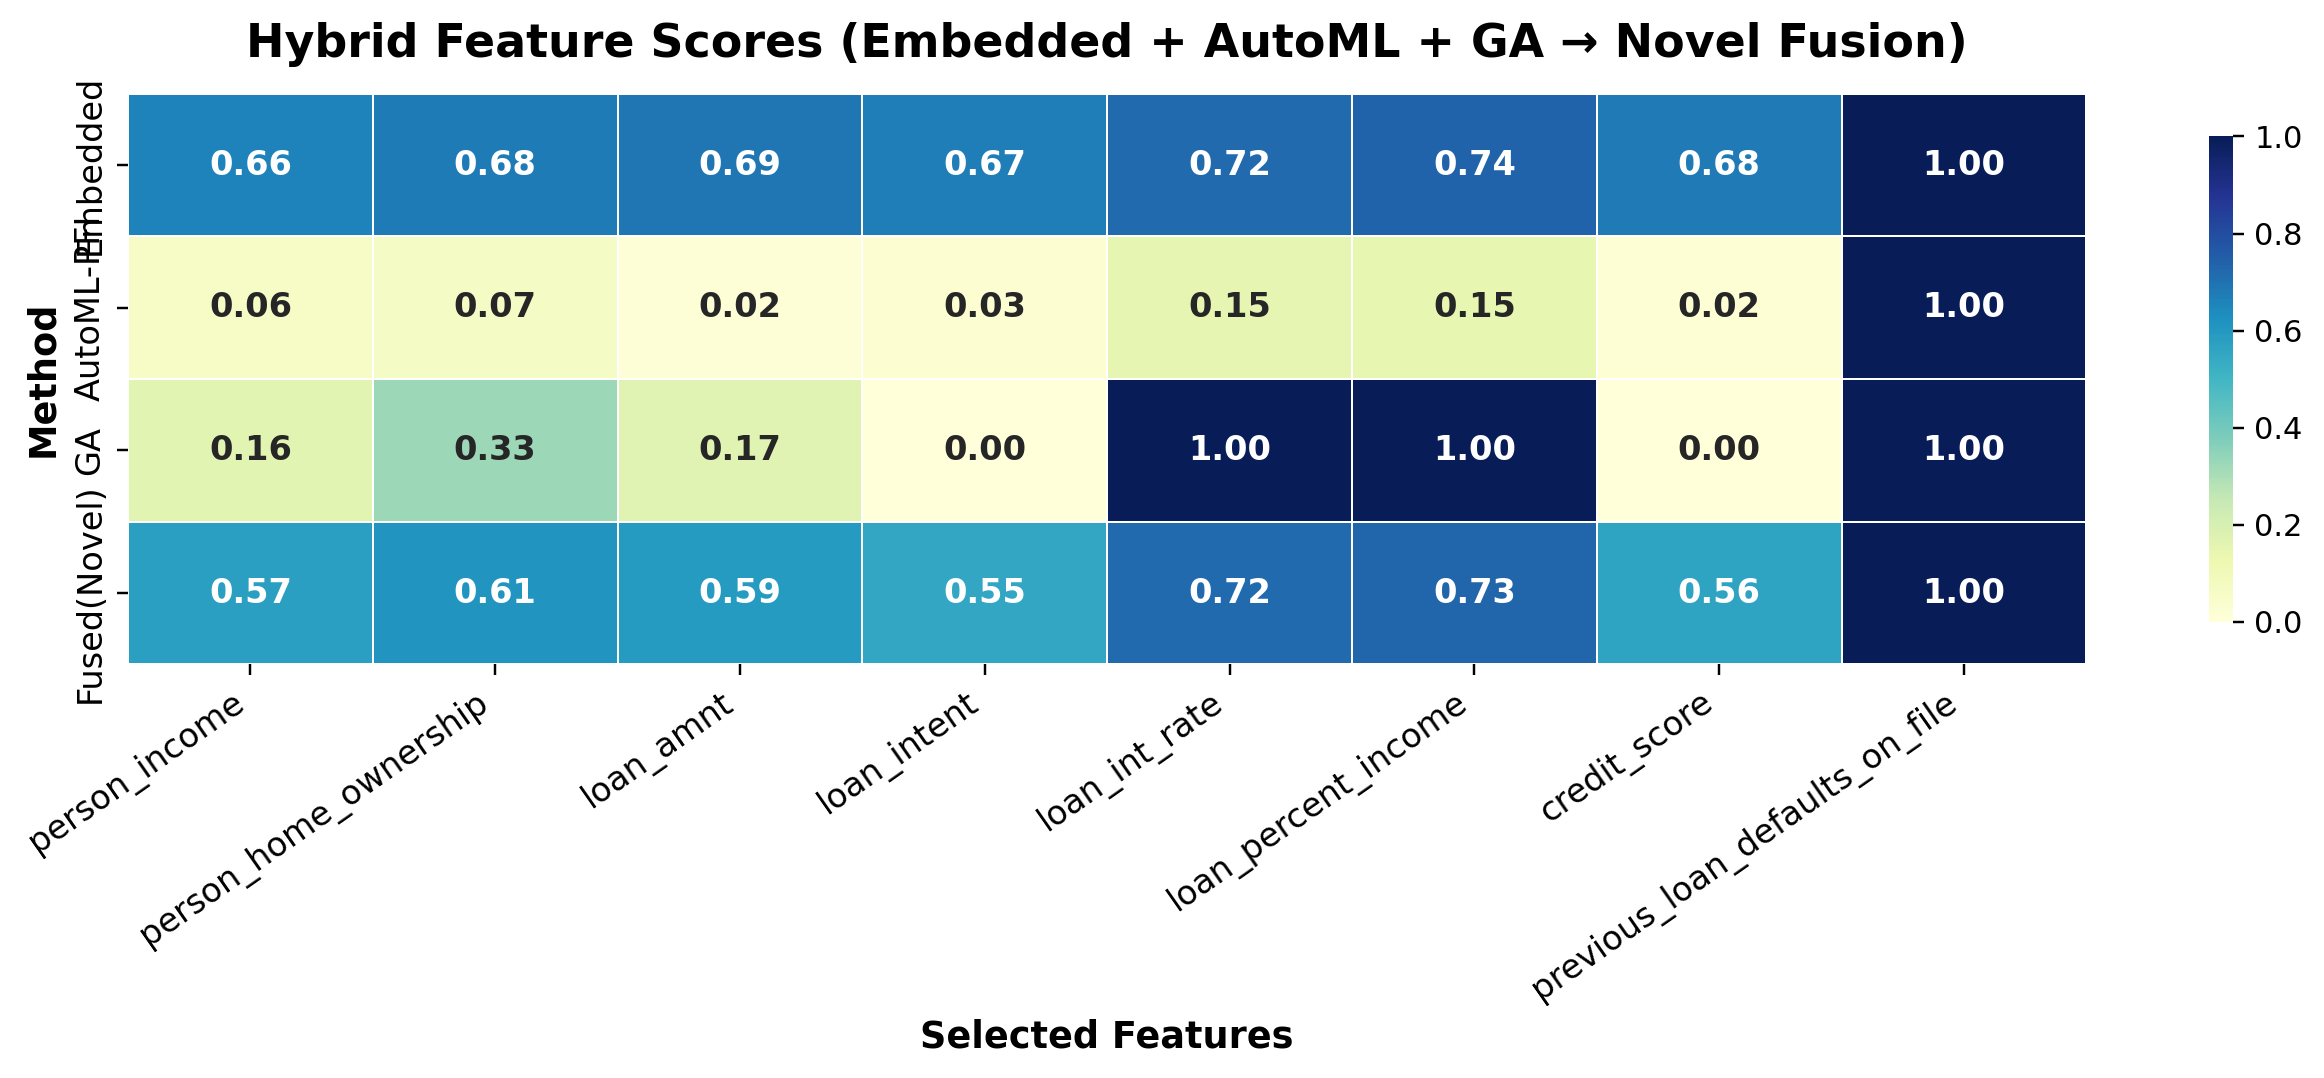

Saved heatmap: hybrid_feature_heatmap.png


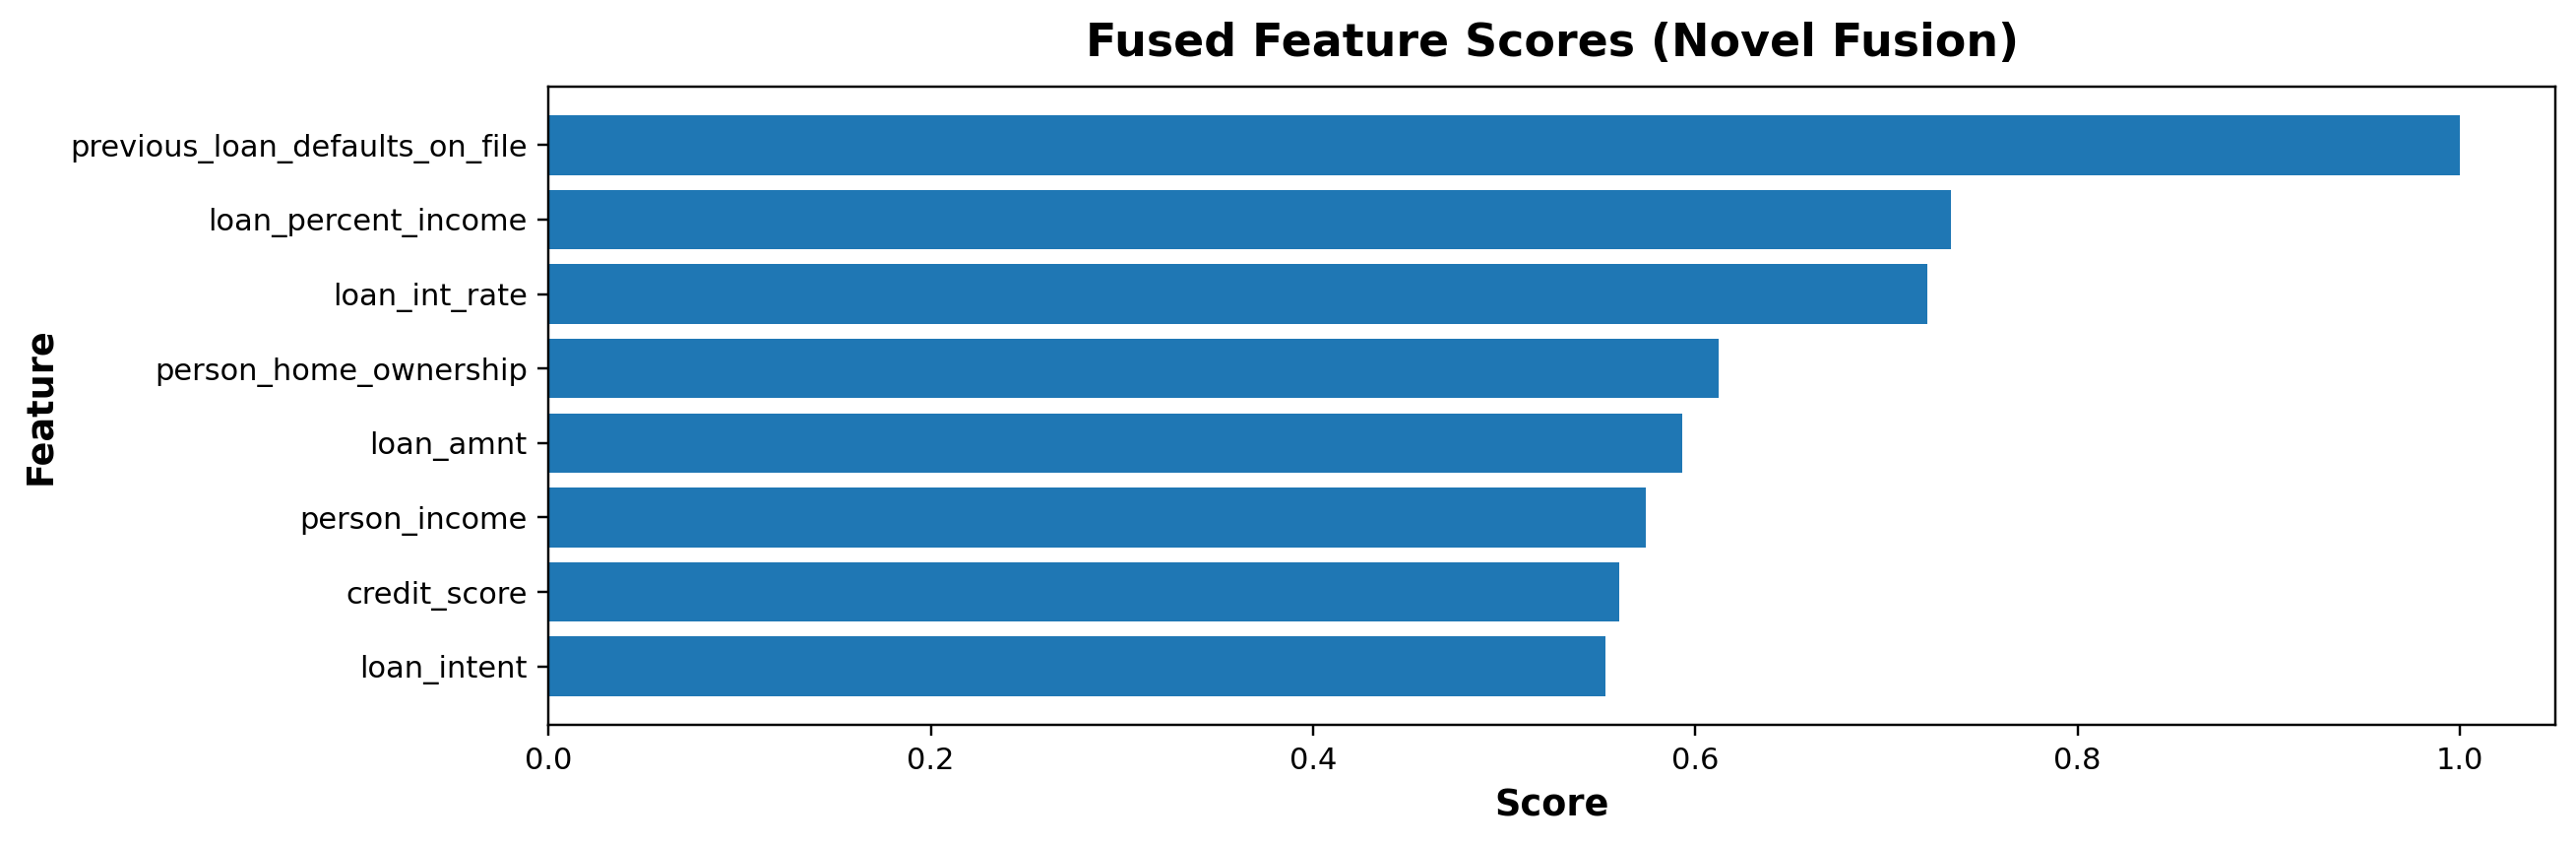

Saved fused score plot: fused_feature_scores.png

Saved selected dataset: train_80_selected_hybrid.csv


In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

from dataclasses import dataclass
from typing import List, Dict, Tuple, Optional

from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler, PowerTransformer, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score, accuracy_score


# ==========================
# Utility helpers
# ==========================
def _minmax01(x: np.ndarray) -> np.ndarray:
    x = np.asarray(x, dtype=float)
    mn, mx = np.min(x), np.max(x)
    return (x - mn) / (mx - mn + 1e-12)

def _sigmoid(x: np.ndarray) -> np.ndarray:
    return 1.0 / (1.0 + np.exp(-x))

def _mad(x: np.ndarray) -> float:
    x = np.asarray(x, dtype=float)
    med = np.median(x)
    return float(np.median(np.abs(x - med)) + 1e-12)

def _is_binary(y: np.ndarray) -> bool:
    uniq = np.unique(y)
    return len(uniq) == 2

def _safe_auc(y_true, y_score) -> float:
    # roc_auc_score fails if only one class in a fold; guard by returning 0.5
    try:
        return roc_auc_score(y_true, y_score)
    except Exception:
        return 0.5


# ==========================
# Config
# ==========================
@dataclass
class HybridFSConfig:
    # Embedded stability selector
    stability_bootstraps: int = 30
    stability_subsample: float = 0.75
    elasticnet_C: float = 1.0
    elasticnet_l1_ratio: float = 0.7
    coef_eps: float = 1e-6

    # AutoML-style selector (lightweight)
    automl_folds: int = 3
    perm_repeats: int = 5
    beta_softmax: float = 6.0

    # GA selector
    ga_folds: int = 3
    ga_pop_size: int = 24
    ga_generations: int = 12
    ga_tournament_k: int = 3
    ga_elite_frac: float = 0.25
    ga_mutation_rate: Optional[float] = None  # default -> 1/d
    ga_crossover_rate: float = 0.9
    ga_lambda_sparsity: float = 0.15
    ga_gamma_weight: float = 6.0

    # Fusion (novel)
    fusion_eta_var: float = 0.25
    fusion_kappa: float = 0.35
    tau_min: float = 0.50
    tau_max: float = 0.92

    # Final selection caps
    min_features: int = 8
    max_features: int = 20

    # Plotting
    fig_dpi: int = 220
    font_size: int = 11


# ==========================
# Main Hybrid Selector
# ==========================
class ICMLHybridFeatureSelector:
    """
    Strong Hybrid Feature Selection:
      - Embedded-in-transformation selector: PowerTransformer + ElasticNet Logistic + Stability selection
      - AutoML selector: Multi-model CV + performance-weighted permutation importance
      - GA selector: CV fitness with sparsity penalty
      - Novel tri-fusion with variance-penalization + adaptive robust threshold
    """

    def __init__(self, cfg: HybridFSConfig = HybridFSConfig(), random_state: int = 42):
        self.cfg = cfg
        self.random_state = random_state

        # Outputs
        self.feature_names_: List[str] = []
        self.emb_score_: Optional[np.ndarray] = None     # stability freq π_j
        self.aml_score_: Optional[np.ndarray] = None     # automl aggregated score
        self.ga_score_: Optional[np.ndarray] = None      # inclusion prob
        self.fused_score_: Optional[np.ndarray] = None   # φ_j

        self.emb_selected_: List[int] = []
        self.aml_selected_: List[int] = []
        self.ga_selected_: List[int] = []
        self.selected_: List[int] = []

        self.model_weights_: Dict[str, float] = {}

    # -------- Embedded stability selector --------
    def _embedded_stability(self, X: np.ndarray, y: np.ndarray) -> np.ndarray:
        rng = np.random.default_rng(self.random_state)

        # "Embedded in transformations": learn a monotonic transform + embedded model
        pt = PowerTransformer(method="yeo-johnson", standardize=True)
        Xt = pt.fit_transform(X)

        n, d = Xt.shape
        B = self.cfg.stability_bootstraps
        subsz = int(max(10, round(self.cfg.stability_subsample * n)))

        select_counts = np.zeros(d, dtype=float)
        coef_mags = np.zeros(d, dtype=float)

        for b in range(B):
            idx = rng.choice(n, size=subsz, replace=False)
            Xb, yb = Xt[idx], y[idx]

            clf = LogisticRegression(
                solver="saga",
                penalty="elasticnet",
                l1_ratio=self.cfg.elasticnet_l1_ratio,
                C=self.cfg.elasticnet_C,
                max_iter=5000,
                n_jobs=-1,
                random_state=self.random_state + b,
            )
            clf.fit(Xb, yb)

            w = np.ravel(clf.coef_)
            coef_mags += np.abs(w)
            select_counts += (np.abs(w) > self.cfg.coef_eps).astype(float)

        pi = select_counts / (B + 1e-12)          # π_j
        coef_mags = coef_mags / (B + 1e-12)       # averaged |w|
        # combine freq + magnitude (still "embedded" view)
        score = 0.65 * _minmax01(pi) + 0.35 * _minmax01(coef_mags)
        self.emb_score_ = score
        return score

    # -------- AutoML selector: multi-model weighted permutation importance --------
    def _automl_weighted_pfi(self, X: np.ndarray, y: np.ndarray, scoring: str) -> np.ndarray:
        d = X.shape[1]
        kf = StratifiedKFold(n_splits=self.cfg.automl_folds, shuffle=True, random_state=self.random_state)

        # Lightweight "AutoML" candidate pool (sklearn-only, robust)
        candidates = [
            ("LogReg_L2", LogisticRegression(solver="lbfgs", penalty="l2", max_iter=4000, n_jobs=-1)),
            ("RF", RandomForestClassifier(n_estimators=400, random_state=self.random_state, n_jobs=-1)),
            ("ExtraTrees", ExtraTreesClassifier(n_estimators=600, random_state=self.random_state, n_jobs=-1)),
            ("HGB", HistGradientBoostingClassifier(random_state=self.random_state)),
        ]

        model_scores = []
        model_importances = []

        for name, model in candidates:
            fold_scores = []
            fold_imps = []

            for tr, va in kf.split(X, y):
                Xtr, Xva = X[tr], X[va]
                ytr, yva = y[tr], y[va]

                model.fit(Xtr, ytr)

                if scoring == "roc_auc":
                    prob = model.predict_proba(Xva)[:, 1] if hasattr(model, "predict_proba") else model.decision_function(Xva)
                    sc = _safe_auc(yva, prob)
                else:
                    pred = model.predict(Xva)
                    sc = accuracy_score(yva, pred)

                fold_scores.append(sc)

                # permutation importance on validation
                pi = permutation_importance(
                    model, Xva, yva,
                    n_repeats=self.cfg.perm_repeats,
                    random_state=self.random_state,
                    scoring=scoring
                ).importances_mean
                fold_imps.append(np.maximum(0.0, pi))

            mean_score = float(np.mean(fold_scores))
            mean_imp = np.mean(np.vstack(fold_imps), axis=0)

            model_scores.append(mean_score)
            model_importances.append(mean_imp)

        model_scores = np.array(model_scores, dtype=float)

        # reliability weights α_m (softmax)
        beta = self.cfg.beta_softmax
        w = np.exp(beta * (model_scores - np.max(model_scores)))
        w = w / (np.sum(w) + 1e-12)

        # aggregate importance
        agg = np.zeros(d, dtype=float)
        for wm, imp in zip(w, model_importances):
            agg += float(wm) * _minmax01(imp)

        self.aml_score_ = _minmax01(agg)

        # store weights for transparency
        self.model_weights_["AutoML_LogReg_L2"] = float(w[0])
        self.model_weights_["AutoML_RF"] = float(w[1])
        self.model_weights_["AutoML_ExtraTrees"] = float(w[2])
        self.model_weights_["AutoML_HGB"] = float(w[3])

        return self.aml_score_

    # -------- GA selector --------
    def _ga_feature_selection(self, X: np.ndarray, y: np.ndarray, scoring: str) -> np.ndarray:
        rng = np.random.default_rng(self.random_state)
        n, d = X.shape

        kf = StratifiedKFold(n_splits=self.cfg.ga_folds, shuffle=True, random_state=self.random_state)

        # evaluator (fast + stable)
        base = LogisticRegression(solver="lbfgs", max_iter=4000, n_jobs=-1)

        lam = self.cfg.ga_lambda_sparsity
        mut_rate = self.cfg.ga_mutation_rate if self.cfg.ga_mutation_rate is not None else (1.0 / d)

        cache: Dict[bytes, float] = {}

        def cv_score(mask: np.ndarray) -> float:
            if mask.sum() == 0:
                return 0.0

            key = mask.tobytes()
            if key in cache:
                return cache[key]

            Xs = X[:, mask.astype(bool)]
            fold_scores = []
            for tr, va in kf.split(Xs, y):
                Xtr, Xva = Xs[tr], Xs[va]
                ytr, yva = y[tr], y[va]
                base.fit(Xtr, ytr)

                if scoring == "roc_auc":
                    prob = base.predict_proba(Xva)[:, 1]
                    fold_scores.append(_safe_auc(yva, prob))
                else:
                    pred = base.predict(Xva)
                    fold_scores.append(accuracy_score(yva, pred))

            sc = float(np.mean(fold_scores))
            cache[key] = sc
            return sc

        def fitness(mask: np.ndarray) -> float:
            sc = cv_score(mask)
            spars = float(mask.sum()) / float(d)
            return sc - lam * spars  # Eq (6)

        # init population near target density
        target = min(max(self.cfg.min_features, int(np.sqrt(n))), self.cfg.max_features)
        p_on = target / max(d, 1)

        pop = (rng.random((self.cfg.ga_pop_size, d)) < p_on).astype(np.int8)
        # ensure not all-zero
        for i in range(pop.shape[0]):
            if pop[i].sum() == 0:
                pop[i, rng.integers(0, d)] = 1

        def tournament_select(pop, fitvals):
            idxs = rng.integers(0, len(pop), size=self.cfg.ga_tournament_k)
            best = idxs[np.argmax(fitvals[idxs])]
            return pop[best].copy()

        def crossover(a, b):
            if rng.random() > self.cfg.ga_crossover_rate:
                return a.copy(), b.copy()
            mask = rng.random(d) < 0.5
            c1 = np.where(mask, a, b).astype(np.int8)
            c2 = np.where(mask, b, a).astype(np.int8)
            if c1.sum() == 0: c1[rng.integers(0, d)] = 1
            if c2.sum() == 0: c2[rng.integers(0, d)] = 1
            return c1, c2

        def mutate(x):
            flips = rng.random(d) < mut_rate
            x = x.copy()
            x[flips] = 1 - x[flips]
            if x.sum() == 0:
                x[rng.integers(0, d)] = 1
            return x

        # evolution
        for g in range(self.cfg.ga_generations):
            fitvals = np.array([fitness(ind) for ind in pop], dtype=float)

            # elitism
            elite_n = max(1, int(self.cfg.ga_elite_frac * len(pop)))
            elite_idx = np.argsort(fitvals)[-elite_n:]
            elites = pop[elite_idx].copy()

            new_pop = [elites[i] for i in range(elite_n)]
            while len(new_pop) < len(pop):
                p1 = tournament_select(pop, fitvals)
                p2 = tournament_select(pop, fitvals)
                c1, c2 = crossover(p1, p2)
                c1 = mutate(c1)
                if len(new_pop) < len(pop):
                    new_pop.append(c1)
                if len(new_pop) < len(pop):
                    c2 = mutate(c2)
                    new_pop.append(c2)

            pop = np.array(new_pop[:len(pop)], dtype=np.int8)

        # final elites -> inclusion probability p^ga
        fitvals = np.array([fitness(ind) for ind in pop], dtype=float)
        elite_n = max(2, int(self.cfg.ga_elite_frac * len(pop)))
        elite_idx = np.argsort(fitvals)[-elite_n:]
        elites = pop[elite_idx].astype(float)
        elite_fit = fitvals[elite_idx]

        # weights ω_k = exp(γF_k)
        gamma = self.cfg.ga_gamma_weight
        w = np.exp(gamma * (elite_fit - np.max(elite_fit)))
        w = w / (np.sum(w) + 1e-12)

        p_ga = (w.reshape(-1, 1) * elites).sum(axis=0)  # Eq (7)
        self.ga_score_ = _minmax01(p_ga)
        return self.ga_score_

    # -------- score-based fusion (novel) --------
    def _fuse(self, emb: np.ndarray, aml: np.ndarray, ga: np.ndarray, n: int, d: int) -> Tuple[np.ndarray, float]:
        e = _minmax01(emb)
        a = _minmax01(aml)
        g = _minmax01(ga)

        # compute method weights using their "global strength"
        # (practical proxy: mean score level) -> softmax
        global_strength = np.array([e.mean(), a.mean(), g.mean()], dtype=float)
        w = np.exp(5.0 * (global_strength - global_strength.max()))
        w = w / (w.sum() + 1e-12)
        we, wa, wg = map(float, w)

        # variance penalty across methods per feature
        var = np.var(np.vstack([e, a, g]), axis=0)

        # Novel Eq (N1)
        eta = self.cfg.fusion_eta_var
        fused = _sigmoid(we * e + wa * a + wg * g - eta * var)
        fused = _minmax01(fused)

        # Novel Eq (N2)
        kappa = self.cfg.fusion_kappa
        tau = np.quantile(fused, 0.75) + kappa * _mad(fused) * np.sqrt(np.log(max(d, 2)) / max(n, 5))
        tau = float(np.clip(tau, self.cfg.tau_min, self.cfg.tau_max))

        return fused, tau

    def fit(self, X: np.ndarray, y: np.ndarray, feature_names: List[str]):
        self.feature_names_ = list(feature_names)

        # choose scoring
        scoring = "roc_auc" if _is_binary(y) else "accuracy"

        # 1) Embedded (stability)
        emb = self._embedded_stability(X, y)

        # 2) AutoML selector
        aml = self._automl_weighted_pfi(X, y, scoring=scoring)

        # 3) GA selector
        ga = self._ga_feature_selection(X, y, scoring=scoring)

        # 4) Novel fusion
        fused, tau = self._fuse(emb, aml, ga, n=X.shape[0], d=X.shape[1])
        self.fused_score_ = fused

        # preliminary selection by threshold
        idx = np.where(fused >= tau)[0].tolist()

        # enforce caps
        if len(idx) < self.cfg.min_features:
            idx = np.argsort(fused)[-self.cfg.min_features:].tolist()
        if len(idx) > self.cfg.max_features:
            idx = np.argsort(fused)[-self.cfg.max_features:].tolist()

        self.selected_ = sorted(idx)

        # method-specific "selected" (top-k by each method)
        def topk(score, k):
            k = min(k, len(score))
            return np.argsort(score)[-k:].tolist()

        k_ref = min(self.cfg.max_features, max(self.cfg.min_features, 12))
        self.emb_selected_ = topk(emb, k_ref)
        self.aml_selected_ = topk(aml, k_ref)
        self.ga_selected_ = topk(ga, k_ref)

        self.model_weights_["Fusion_we"] = float(_minmax01(np.array([emb.mean()]))[0])  # informational
        self.model_weights_["Fusion_tau"] = float(tau)

        return self

    def transform(self, X: np.ndarray) -> np.ndarray:
        return X[:, self.selected_]

    def fit_transform(self, X: np.ndarray, y: np.ndarray, feature_names: List[str]) -> np.ndarray:
        return self.fit(X, y, feature_names).transform(X)

    # -------- plotting --------
    def plot_heatmap(self, save_path="hybrid_feature_heatmap.png", show_plot=True):
        if self.fused_score_ is None:
            print("Call fit() first.")
            return None

        # show only selected features (clean + readable)
        sel = self.selected_
        cols = [self.feature_names_[i] for i in sel]

        mat = np.vstack([
            _minmax01(self.emb_score_)[sel],
            _minmax01(self.aml_score_)[sel],
            _minmax01(self.ga_score_)[sel],
            _minmax01(self.fused_score_)[sel],
        ])

        df = pd.DataFrame(mat, index=["Embedded", "AutoML-PFI", "GA", "Fused(Novel)"], columns=cols)

        plt.figure(figsize=(max(12, 0.6 * len(cols)), 5), dpi=self.cfg.fig_dpi)
        cmap = sns.color_palette("YlGnBu", as_cmap=True)
        ax = sns.heatmap(
            df, annot=True, fmt=".2f", cmap=cmap, linewidths=0.6,
            cbar_kws={"shrink": 0.85}, annot_kws={'size': 11, 'weight': 'bold'}
        )
        plt.title("Hybrid Feature Scores (Embedded + AutoML + GA → Novel Fusion)", fontsize=15, fontweight="bold", pad=12)
        plt.xlabel("Selected Features", fontsize=12, fontweight="bold")
        plt.ylabel("Method", fontsize=12, fontweight="bold")
        plt.xticks(rotation=35, ha="right", fontsize=11)
        plt.yticks(fontsize=11)
        plt.tight_layout()
        plt.savefig(save_path, dpi=300, bbox_inches="tight")
        if show_plot:
            plt.show()
        else:
            plt.close()
        print(f"Saved heatmap: {save_path}")
        return df

    def plot_fused_bar(self, save_path="fused_feature_scores.png", show_plot=True):
        if self.fused_score_ is None:
            print("Call fit() first.")
            return

        sel = self.selected_
        names = [self.feature_names_[i] for i in sel]
        scores = self.fused_score_[sel]

        order = np.argsort(scores)
        names = [names[i] for i in order]
        scores = scores[order]

        plt.figure(figsize=(12, max(4, 0.35 * len(names))), dpi=self.cfg.fig_dpi)
        plt.barh(names, scores)
        plt.title("Fused Feature Scores (Novel Fusion)", fontsize=15, fontweight="bold", pad=10)
        plt.xlabel("Score", fontsize=12, fontweight="bold")
        plt.ylabel("Feature", fontsize=12, fontweight="bold")
        plt.tight_layout()
        plt.savefig(save_path, dpi=300, bbox_inches="tight")
        if show_plot:
            plt.show()
        else:
            plt.close()
        print(f"Saved fused score plot: {save_path}")


# ==========================
# MAIN EXECUTION (train_80.csv)
# ==========================
def main():
    # Load
    df = pd.read_csv("train_80.csv")
    if "loan_status" not in df.columns:
        raise ValueError("Expected target column named 'loan_status' in train_80.csv")

    X_df = df.drop(columns=["loan_status"])
    y_raw = df["loan_status"].values

    # Encode label safely (supports strings too)
    le = LabelEncoder()
    y = le.fit_transform(y_raw)

    feature_names = X_df.columns.tolist()

    # Standardize (keep it separate, no leakage if you later apply same scaler to test)
    scaler = StandardScaler()
    X = scaler.fit_transform(X_df.values)

    # Run selector
    cfg = HybridFSConfig(
        min_features=8,
        max_features=18,           # tighten if you want fewer features
        ga_generations=12,         # increase for stronger GA search (e.g., 20–40)
        ga_pop_size=24,            # increase for stronger GA search (e.g., 40–80)
        stability_bootstraps=30,
        perm_repeats=5
    )
    selector = ICMLHybridFeatureSelector(cfg=cfg, random_state=42)
    X_sel = selector.fit_transform(X, y, feature_names)

    # Print results
    def names(idxs): return [feature_names[i] for i in sorted(idxs)]

    print("\n==================== Method-wise Top Features ====================")
    print("Embedded (top):", names(selector.emb_selected_))
    print("AutoML-PFI (top):", names(selector.aml_selected_))
    print("GA (top):", names(selector.ga_selected_))

    print("\n==================== Final Selected (Novel Fusion) ====================")
    final_names = names(selector.selected_)
    print(final_names)
    print(f"Selected {len(final_names)} / {len(feature_names)} features.")

    print("\n==================== AutoML Model Weights (Reliability) ====================")
    for k, v in selector.model_weights_.items():
        if k.startswith("AutoML_"):
            print(f"{k}: {v:.4f}")
    print(f"Fusion threshold τ (stored): {selector.model_weights_.get('Fusion_tau', None)}")

    # Plots
    selector.plot_heatmap(save_path="hybrid_feature_heatmap.png", show_plot=True)
    selector.plot_fused_bar(save_path="fused_feature_scores.png", show_plot=True)

    # Optional: save selected dataframe
    out = pd.DataFrame(X_sel, columns=final_names)
    out["loan_status"] = y_raw
    out.to_csv("train_80_selected_hybrid.csv", index=False)
    print("\nSaved selected dataset: train_80_selected_hybrid.csv")


if __name__ == "__main__":
    main()

In [15]:
import pandas as pd
from google.colab import files

# Define the selected features and the target column
selected_features = ['person_income', 'person_home_ownership', 'loan_amnt', 'loan_intent', 'loan_int_rate', 'loan_percent_income', 'credit_score', 'previous_loan_defaults_on_file','loan_status']

# Load the train and test datasets
train_df = pd.read_csv('train_80.csv')
test_df = pd.read_csv('test_20.csv')

# Select only the desired columns
train_df_selected = train_df[selected_features]
test_df_selected = test_df[selected_features]

# Define new filenames
train_output_filename = "train_80_selected_features.csv"
test_output_filename = "test_20_selected_features.csv"

# Save the new DataFrames to CSV files
train_df_selected.to_csv(train_output_filename, index=False)
test_df_selected.to_csv(test_output_filename, index=False)

print(f"'{train_output_filename}' has been created with selected features.")
print(f"'{test_output_filename}' has been created with selected features.")

# Optionally, download the files
# files.download(train_output_filename)
# files.download(test_output_filename)
# print(f"'{train_output_filename}' downloaded.")
# print(f"'{test_output_filename}' downloaded.")


'train_80_selected_features.csv' has been created with selected features.
'test_20_selected_features.csv' has been created with selected features.


In [16]:
df = pd.read_csv("train_80_selected_features.csv")
df.head()

,person_income,person_home_ownership,loan_amnt,loan_intent,loan_int_rate,loan_percent_income,credit_score,previous_loan_defaults_on_file,loan_status
0,0.007079,2,0.113043,5,0.039095,0.106061,0.578261,1,0.0
1,0.005265,3,0.304348,5,0.383402,0.363636,0.530435,1,0.0
2,0.032386,0,0.275362,5,0.498628,0.060606,0.539130,1,0.0
3,0.012278,0,0.159420,3,0.553498,0.090909,0.634783,0,0.0
4,0.009041,0,0.217391,4,0.349108,0.166667,0.552174,1,0.0


In [17]:
# Assuming df is your dataframe and 'target' is your target column
X = df.drop('loan_status', axis=1)  # Features
y = df['loan_status']  # Target

In [18]:
df_selected = df.drop('loan_status', axis=1)
X = df_selected  # Now X will also exclude 'PCOS_YN'
y = df['loan_status']

# **Random Over Sampler**

In [19]:
#Random data shuffle
from imblearn.over_sampling import RandomOverSampler
X_over,y_over=RandomOverSampler().fit_resample(X,y)

# **Bar Before ROS and after ROS**

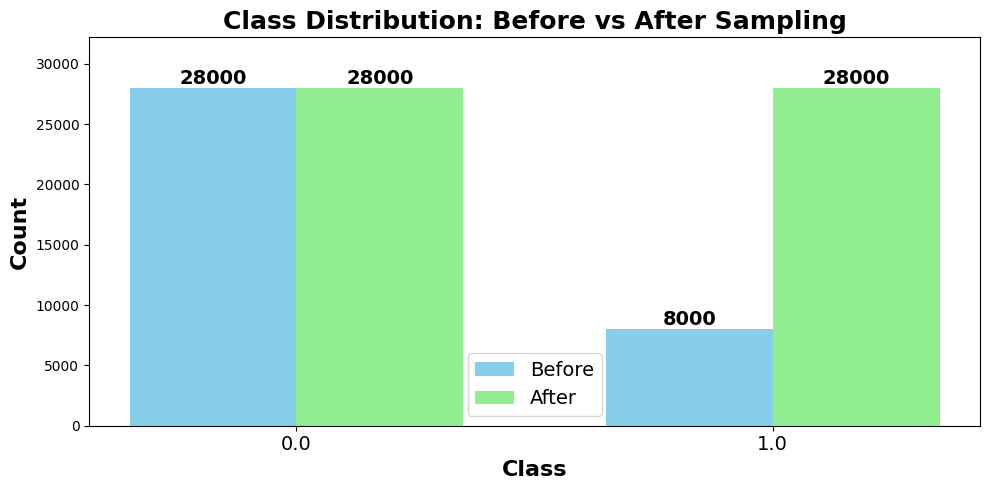

In [20]:
import pandas as pd
import matplotlib.pyplot as plt
from imblearn.over_sampling import RandomOverSampler

# Load data
df = pd.read_csv('train_80_selected_features.csv')
X = df.drop('loan_status', axis=1)
y = df['loan_status']

# ===== Before Sampling =====
counts_before = y.value_counts().sort_index()

# ===== Apply RandomOverSampler =====
ros = RandomOverSampler(random_state=42)
X_ros, y_ros = ros.fit_resample(X, y)
counts_after = pd.Series(y_ros).value_counts().sort_index()

# Save resampled dataset
df_res = pd.concat([pd.DataFrame(X_ros, columns=X.columns), pd.Series(y_ros, name='loan_status')], axis=1)
df_res.to_csv('dataset.csv', index=False)

# ===== Combined Bar Chart =====
classes = sorted(set(y.unique()) | set(y_ros.unique()))
x = range(len(classes))
width = 0.35  # width of bars

plt.figure(figsize=(10, 5))
bars1 = plt.bar([i - width/2 for i in x], [counts_before.get(cls, 0) for cls in classes], width=width, label='Before', color='skyblue')
bars2 = plt.bar([i + width/2 for i in x], [counts_after.get(cls, 0) for cls in classes], width=width, label='After', color='lightgreen')

# Text annotations with larger fontsize
for bar in bars1:
    height = bar.get_height()
    if height > 0:
        plt.text(bar.get_x() + bar.get_width()/2, height + 2, str(int(height)), ha='center', va='bottom', fontsize=14, fontweight='bold')
for bar in bars2:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, height + 2, str(int(height)), ha='center', va='bottom', fontsize=14, fontweight='bold')

plt.xticks(x, classes, fontsize=14)
plt.xlabel('Class', fontsize=16, fontweight='bold')
plt.ylabel('Count', fontsize=16, fontweight='bold')
plt.title('Class Distribution: Before vs After Sampling', fontsize=18, fontweight='bold')
plt.ylim(0, max(counts_before.max(), counts_after.max()) * 1.15)
plt.legend(fontsize=14)
plt.tight_layout()
plt.show()


In [21]:
#Split data to train set and test set
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X_over, y_over, test_size=0.20, random_state=42, stratify=y_over)
print(f'Train shape : {X_train.shape}\nTest shape: {X_test.shape}')

Train shape : (44800, 8)
Test shape: (11200, 8)


In [22]:
# scikit-learn classifiers
!pip install catboost # Already installed in previous execution
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression, RidgeClassifier, PassiveAggressiveClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier, ExtraTreesClassifier # Import ExtraTreesClassifier from sklearn.ensemble
from sklearn.ensemble import HistGradientBoostingClassifier, StackingClassifier, VotingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB, MultinomialNB, BernoulliNB, ComplementNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.neural_network import MLPClassifier
from sklearn.neighbors import NearestCentroid

# Gradient boosting frameworks
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
import lightgbm as lgb
from sklearn import metrics
from sklearn.ensemble import GradientBoostingClassifier

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.2/99.2 MB 10.3 MB/s eta 0:00:00


# **Model**

# **RF**

Starting 10-fold CV with RandomizedSearchCV tuning...

=== Fold 1 ===
Best params: {'n_estimators': 50, 'min_samples_split': 2, 'min_samples_leaf': 2, 'max_depth': 18, 'bootstrap': False}
Accuracy:  0.9609
Precision: 0.9617
Recall:    0.9609
F1-score:  0.9609
ROC AUC:   0.9949

=== Fold 2 ===
Best params: {'n_estimators': 50, 'min_samples_split': 2, 'min_samples_leaf': 2, 'max_depth': 18, 'bootstrap': False}
Accuracy:  0.9556
Precision: 0.9562
Recall:    0.9556
F1-score:  0.9556
ROC AUC:   0.9936

=== Fold 3 ===
Best params: {'n_estimators': 50, 'min_samples_split': 2, 'min_samples_leaf': 2, 'max_depth': 18, 'bootstrap': False}
Accuracy:  0.9578
Precision: 0.9589
Recall:    0.9578
F1-score:  0.9578
ROC AUC:   0.9932

=== Fold 4 ===
Best params: {'n_estimators': 50, 'min_samples_split': 2, 'min_samples_leaf': 2, 'max_depth': 18, 'bootstrap': False}
Accuracy:  0.9607
Precision: 0.9612
Recall:    0.9607
F1-score:  0.9607
ROC AUC:   0.9947

=== Fold 5 ===
Best params: {'n_estimators': 50, 

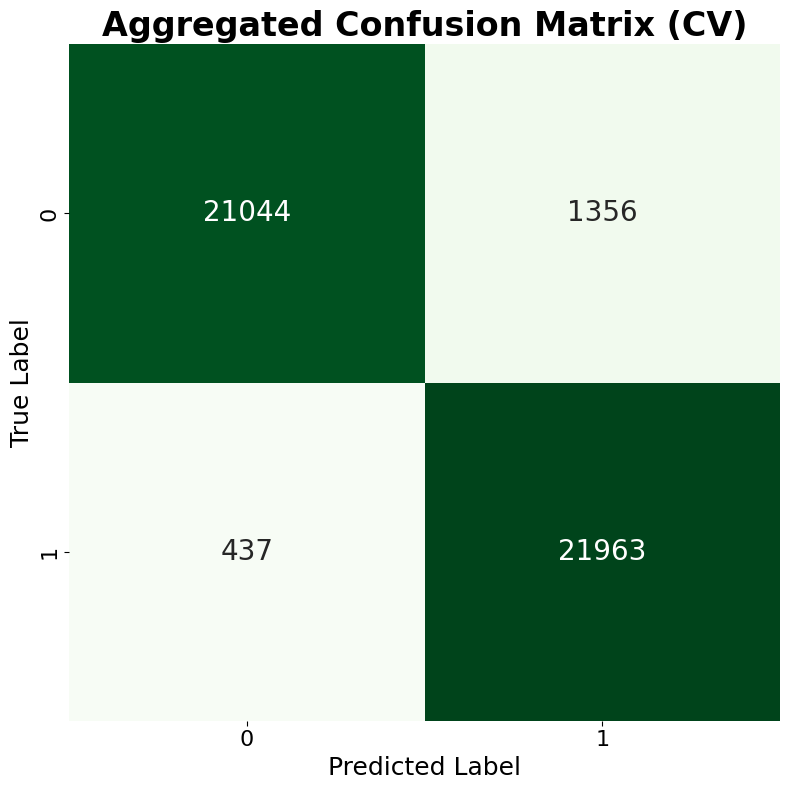

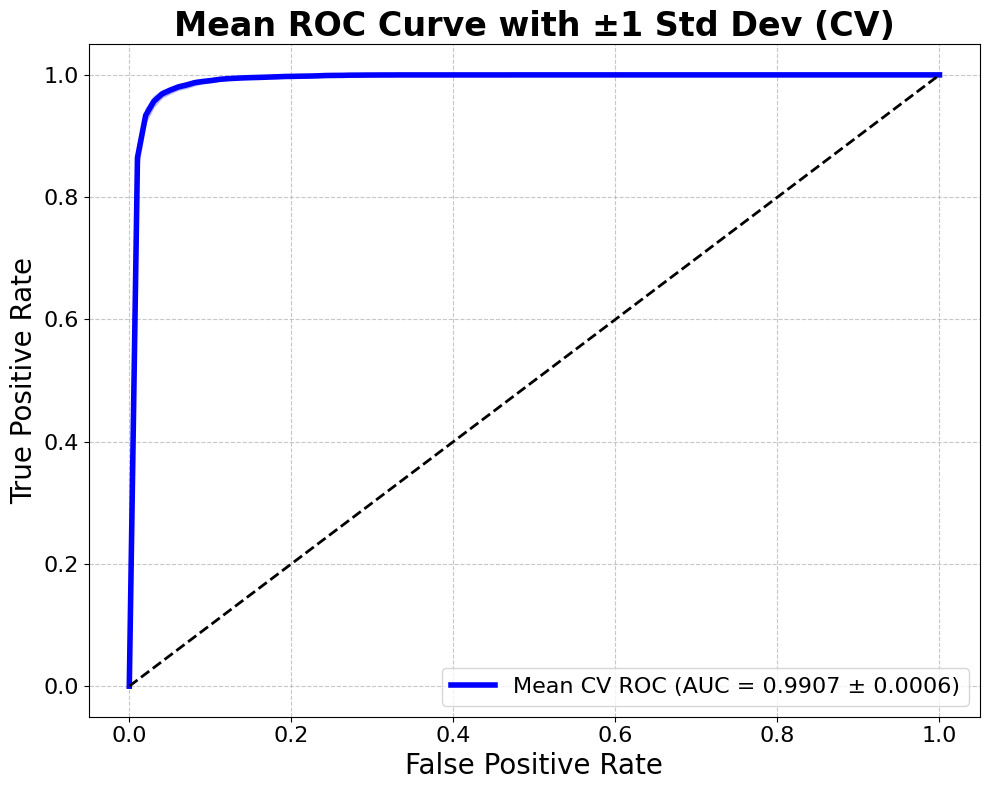


Final hyperparameters selected:
{'bootstrap': False, 'max_depth': 18, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 50}

=== Test Set Performance ===
              precision    recall  f1-score   support

         0.0       0.99      0.94      0.96      5600
         1.0       0.94      0.99      0.96      5600

    accuracy                           0.96     11200
   macro avg       0.97      0.96      0.96     11200
weighted avg       0.97      0.96      0.96     11200

Accuracy:  0.9641
Precision: 0.9651
Recall:    0.9641
F1-Score:  0.9641
ROC-AUC:   0.9956


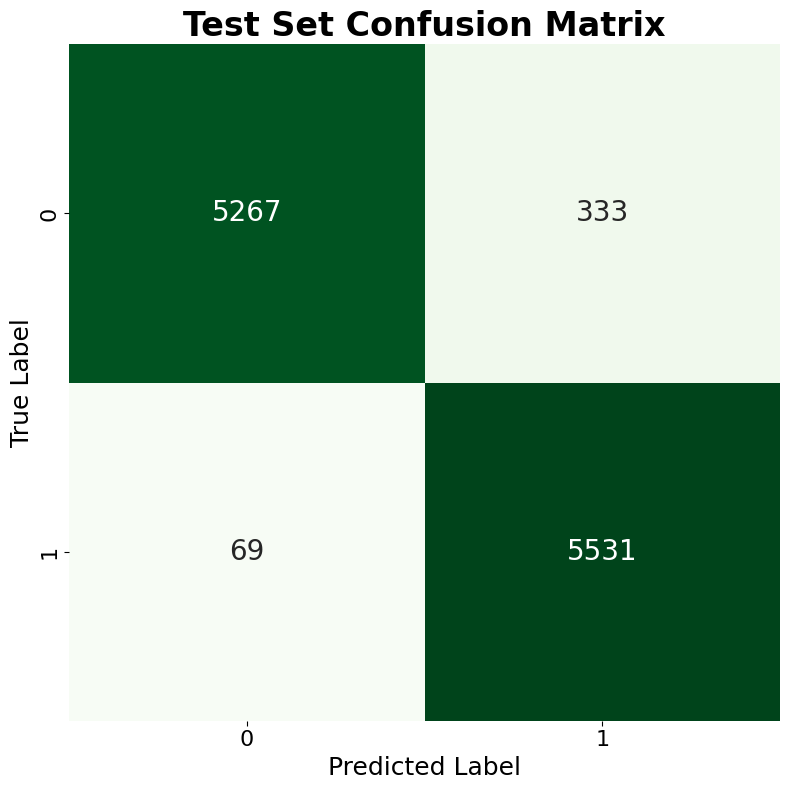

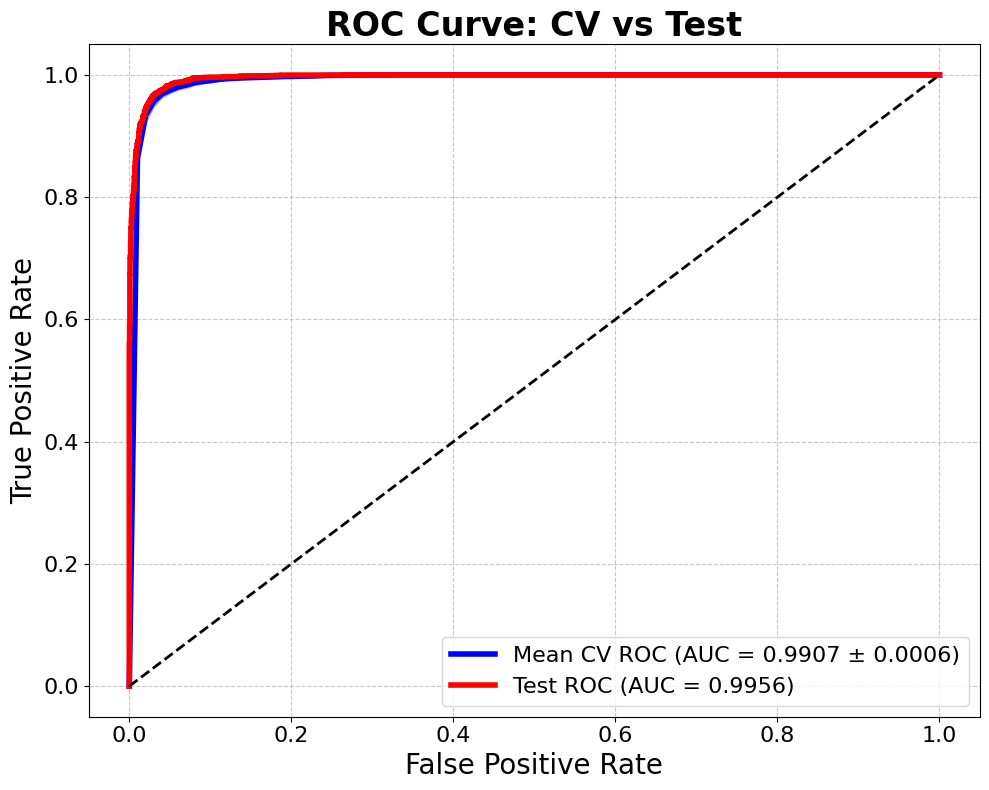

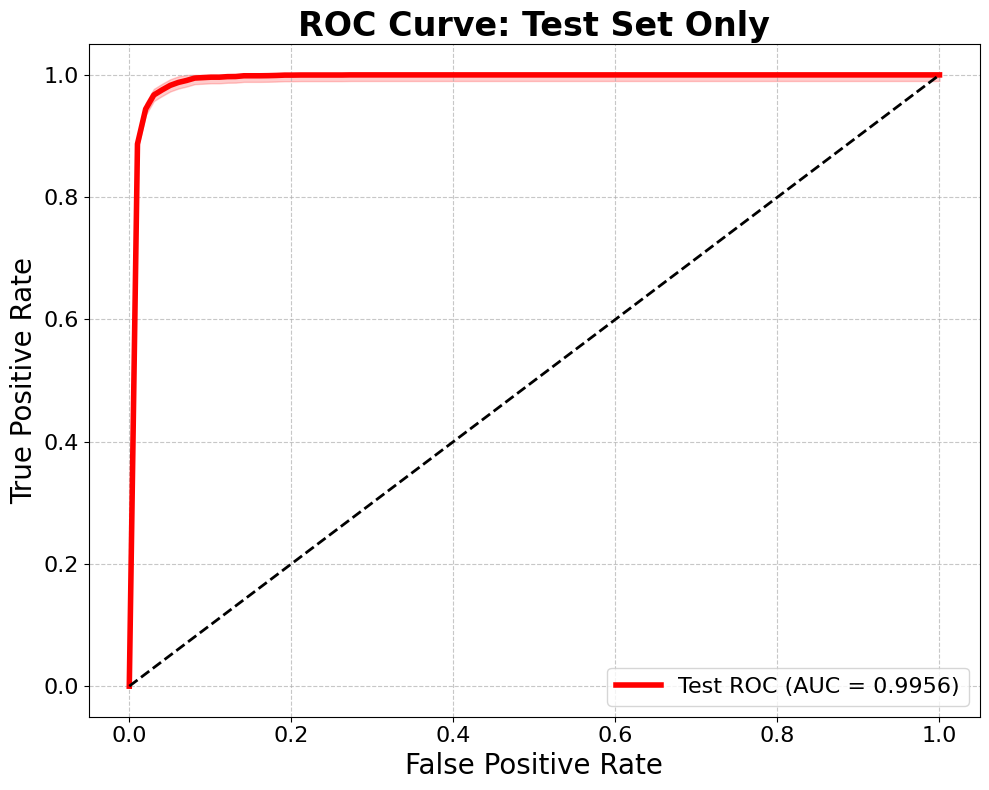


✅ Final model saved as 'random_forest_tuned_10fold.pkl'


In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, classification_report,
                             confusion_matrix, roc_curve, auc)
import joblib
from collections import Counter

# === Assume X_train, y_train, X_test, y_test are defined ===

param_grid = {
    'n_estimators': [50, 100, 150],
    'max_depth': [6, 12, 18],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'bootstrap': [True, False]
}

skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

fold_metrics = []
fold_conf_matrices = []
tprs = []
roc_aucs = []
mean_fpr = np.linspace(0, 1, 100)
best_params_list = []

print("Starting 10-fold CV with RandomizedSearchCV tuning...\n")

for fold, (train_idx, val_idx) in enumerate(skf.split(X_train, y_train), 1):
    print(f"=== Fold {fold} ===")
    X_tr, X_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
    y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]

    rf = RandomForestClassifier(random_state=42)

    rcv = RandomizedSearchCV(
        rf,
        param_distributions=param_grid,
        n_iter=15,
        scoring='accuracy',
        cv=3,
        n_jobs=-1,
        random_state=42,
        verbose=0
    )

    rcv.fit(X_tr, y_tr)
    best_rf = rcv.best_estimator_
    best_params_list.append(rcv.best_params_)

    y_pred = best_rf.predict(X_val)
    y_prob = best_rf.predict_proba(X_val)[:, 1]

    acc = accuracy_score(y_val, y_pred)
    pre = precision_score(y_val, y_pred, average='weighted', zero_division=0)
    rec = recall_score(y_val, y_pred, average='weighted', zero_division=0)
    f1 = f1_score(y_val, y_pred, average='weighted', zero_division=0)
    roc = roc_auc_score(y_val, y_prob)

    fold_metrics.append((acc, pre, rec, f1, roc))

    print(f"Best params: {rcv.best_params_}")
    print(f"Accuracy:  {acc:.4f}")
    print(f"Precision: {pre:.4f}")
    print(f"Recall:    {rec:.4f}")
    print(f"F1-score:  {f1:.4f}")
    print(f"ROC AUC:   {roc:.4f}\n")

    cm = confusion_matrix(y_val, y_pred)
    fold_conf_matrices.append(cm)

    fpr, tpr, _ = roc_curve(y_val, y_prob)
    tprs.append(np.interp(mean_fpr, fpr, tpr))
    tprs[-1][0] = 0.0
    roc_aucs.append(roc)

metrics_array = np.array(fold_metrics)
metrics_names = ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC AUC']

print("=== Cross-validation Summary ===")
for i, metric_name in enumerate(metrics_names):
    mean_val = metrics_array[:, i].mean()
    std_val = metrics_array[:, i].std()
    print(f"{metric_name}: Mean = {mean_val:.4f}, Std = {std_val:.4f}")

sum_cm = np.sum(fold_conf_matrices, axis=0)

# CV Confusion Matrix (Greens)
plt.figure(figsize=(8, 8))
sns.heatmap(sum_cm, annot=True, fmt='d', cmap='Greens', cbar=False,
            annot_kws={"size": 20})
plt.title('Aggregated Confusion Matrix (CV)', fontsize=24, fontweight='bold')
plt.xlabel('Predicted Label', fontsize=18)
plt.ylabel('True Label', fontsize=18)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.tight_layout()
plt.show()

mean_tpr = np.mean(tprs, axis=0)
mean_tpr[-1] = 1.0
mean_auc = auc(mean_fpr, mean_tpr)
std_auc = np.std(roc_aucs)

tprs_upper = np.minimum(mean_tpr + np.std(tprs, axis=0), 1)
tprs_lower = np.maximum(mean_tpr - np.std(tprs, axis=0), 0)

plt.figure(figsize=(10, 8))
plt.plot(mean_fpr, mean_tpr, color='blue', lw=4,
         label=f'Mean CV ROC (AUC = {mean_auc:.4f} ± {std_auc:.4f})')
plt.fill_between(mean_fpr, tprs_lower, tprs_upper, color='blue', alpha=0.2)
plt.plot([0, 1], [0, 1], 'k--', lw=2)

plt.xlabel('False Positive Rate', fontsize=20)
plt.ylabel('True Positive Rate', fontsize=20)
plt.title('Mean ROC Curve with ±1 Std Dev (CV)', fontsize=24, fontweight='bold')
plt.legend(loc='lower right', fontsize=16)
plt.grid(alpha=0.7, linestyle='--')
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.tight_layout()
plt.show()

most_common_params = Counter(tuple(sorted(p.items())) for p in best_params_list).most_common(1)[0][0]
final_params = dict(most_common_params)

print("\nFinal hyperparameters selected:")
print(final_params)

final_model = RandomForestClassifier(random_state=42, **final_params)
final_model.fit(X_train, y_train)

y_test_pred = final_model.predict(X_test)
y_test_prob = final_model.predict_proba(X_test)[:, 1]

acc = accuracy_score(y_test, y_test_pred)
pre = precision_score(y_test, y_test_pred, average='weighted', zero_division=0)
rec = recall_score(y_test, y_test_pred, average='weighted', zero_division=0)
f1 = f1_score(y_test, y_test_pred, average='weighted', zero_division=0)
roc_auc = roc_auc_score(y_test, y_test_prob)

print("\n=== Test Set Performance ===")
print(classification_report(y_test, y_test_pred))
print(f"Accuracy:  {acc:.4f}")
print(f"Precision: {pre:.4f}")
print(f"Recall:    {rec:.4f}")
print(f"F1-Score:  {f1:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")

cm_test = confusion_matrix(y_test, y_test_pred)
plt.figure(figsize=(8, 8))
sns.heatmap(cm_test, annot=True, fmt='d', cmap='Greens', cbar=False,
            annot_kws={"size": 20})
plt.title('Test Set Confusion Matrix', fontsize=24, fontweight='bold')
plt.xlabel('Predicted Label', fontsize=18)
plt.ylabel('True Label', fontsize=18)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.tight_layout()
plt.show()

# === 1) Combined ROC: Mean CV + Test ROC ===
plt.figure(figsize=(10, 8))
plt.plot(mean_fpr, mean_tpr, color='blue', lw=4,
         label=f'Mean CV ROC (AUC = {mean_auc:.4f} ± {std_auc:.4f})')
plt.fill_between(mean_fpr, tprs_lower, tprs_upper, color='blue', alpha=0.2)

fpr_test, tpr_test, _ = roc_curve(y_test, y_test_prob)
plt.plot(fpr_test, tpr_test, color='red', lw=4,
         label=f'Test ROC (AUC = {roc_auc:.4f})')

plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlabel('False Positive Rate', fontsize=20)
plt.ylabel('True Positive Rate', fontsize=20)
plt.title('ROC Curve: CV vs Test', fontsize=24, fontweight='bold')
plt.legend(loc='lower right', fontsize=16)
plt.grid(alpha=0.7, linestyle='--')
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.tight_layout()
plt.show()

# === 2) Separate Test ROC with same smooth design ===
# Interpolate test ROC for smoothness
mean_fpr_test = np.linspace(0, 1, 100)
interp_tpr_test = np.interp(mean_fpr_test, fpr_test, tpr_test)
interp_tpr_test[0] = 0.0
interp_tpr_test[-1] = 1.0

plt.figure(figsize=(10, 8))
plt.plot(mean_fpr_test, interp_tpr_test, color='red', lw=4,
         label=f'Test ROC (AUC = {roc_auc:.4f})')

# Add a narrow shaded band for style consistency
plt.fill_between(mean_fpr_test,
                 np.maximum(interp_tpr_test - 0.01, 0),
                 np.minimum(interp_tpr_test + 0.01, 1),
                 color='red', alpha=0.2)

plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlabel('False Positive Rate', fontsize=20)
plt.ylabel('True Positive Rate', fontsize=20)
plt.title('ROC Curve: Test Set Only', fontsize=24, fontweight='bold')
plt.legend(loc='lower right', fontsize=16)
plt.grid(alpha=0.7, linestyle='--')
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.tight_layout()
plt.show()

# Save model
joblib.dump(final_model, 'random_forest_tuned_10fold.pkl')
print("\n✅ Final model saved as 'random_forest_tuned_10fold.pkl'")


# **KNN**

Starting 10-fold CV with RandomizedSearchCV tuning for KNN...

=== Fold 1 ===
Best params: {'weights': 'distance', 'p': 1, 'n_neighbors': 3, 'metric': 'euclidean', 'leaf_size': 30}
Accuracy:  0.9377
Precision: 0.9429
Recall:    0.9377
F1-score:  0.9375
ROC AUC:   0.9681

=== Fold 2 ===
Best params: {'weights': 'distance', 'p': 1, 'n_neighbors': 3, 'metric': 'euclidean', 'leaf_size': 30}
Accuracy:  0.9297
Precision: 0.9348
Recall:    0.9297
F1-score:  0.9295
ROC AUC:   0.9632

=== Fold 3 ===
Best params: {'weights': 'distance', 'p': 1, 'n_neighbors': 3, 'metric': 'euclidean', 'leaf_size': 30}
Accuracy:  0.9350
Precision: 0.9404
Recall:    0.9350
F1-score:  0.9348
ROC AUC:   0.9649

=== Fold 4 ===
Best params: {'weights': 'distance', 'p': 1, 'n_neighbors': 3, 'metric': 'euclidean', 'leaf_size': 30}
Accuracy:  0.9368
Precision: 0.9410
Recall:    0.9368
F1-score:  0.9367
ROC AUC:   0.9645

=== Fold 5 ===
Best params: {'weights': 'distance', 'p': 1, 'n_neighbors': 3, 'metric': 'euclidean', 

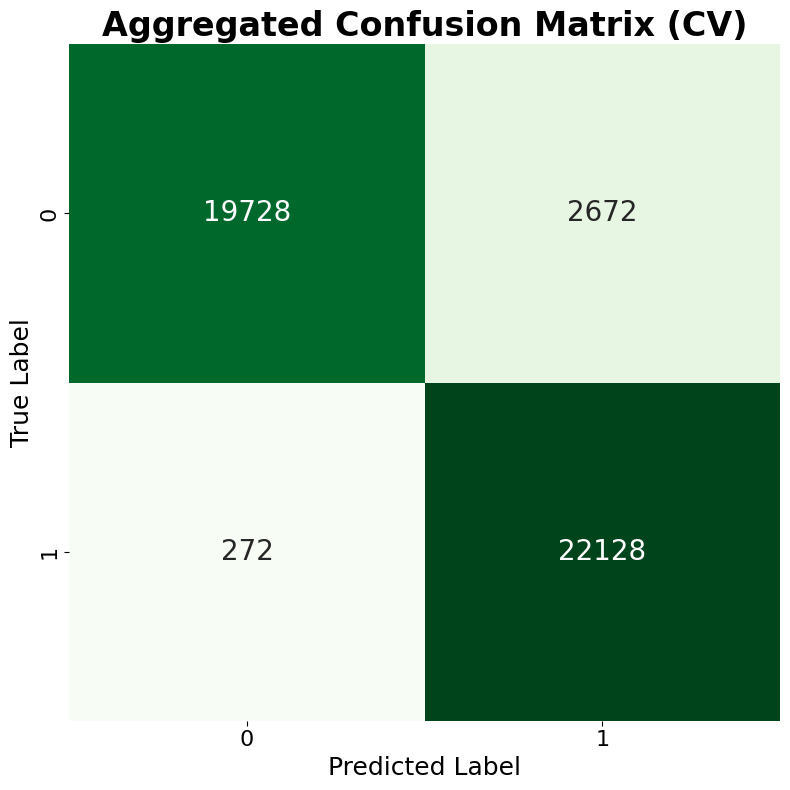

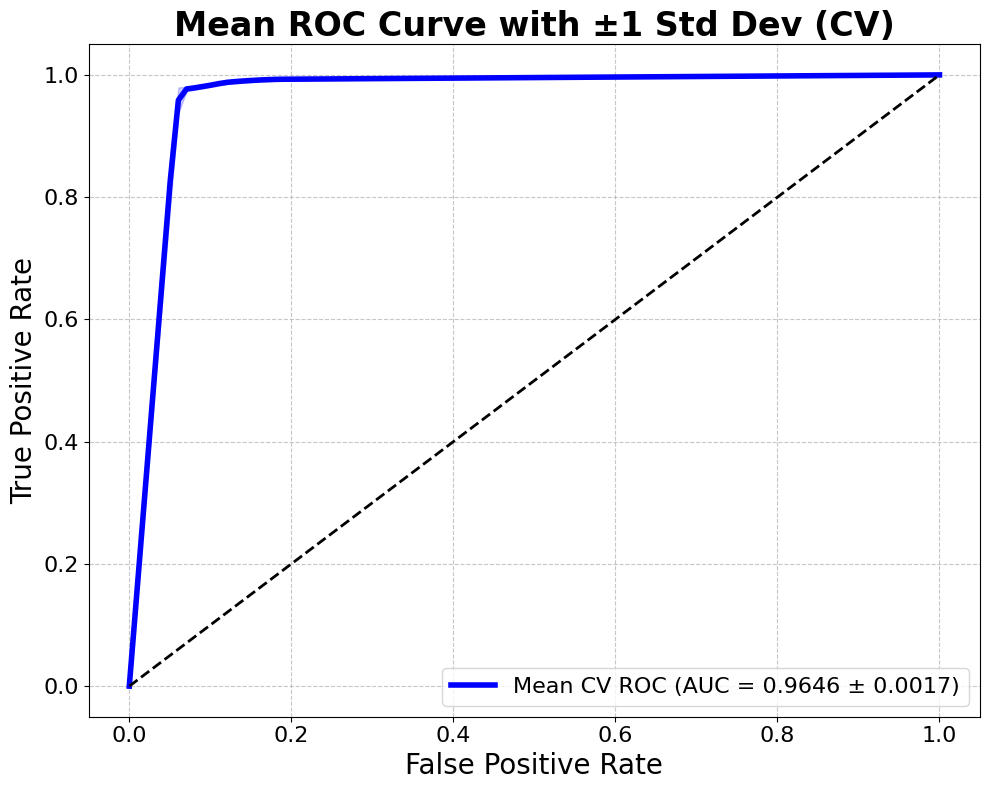


Final hyperparameters selected:
{'leaf_size': 30, 'metric': 'euclidean', 'n_neighbors': 3, 'p': 1, 'weights': 'distance'}

=== Test Set Performance ===
              precision    recall  f1-score   support

         0.0       0.99      0.88      0.93      5600
         1.0       0.89      0.99      0.94      5600

    accuracy                           0.94     11200
   macro avg       0.94      0.94      0.94     11200
weighted avg       0.94      0.94      0.94     11200

Accuracy:  0.9380
Precision: 0.9435
Recall:    0.9380
F1-score:  0.9378
ROC AUC:   0.9667


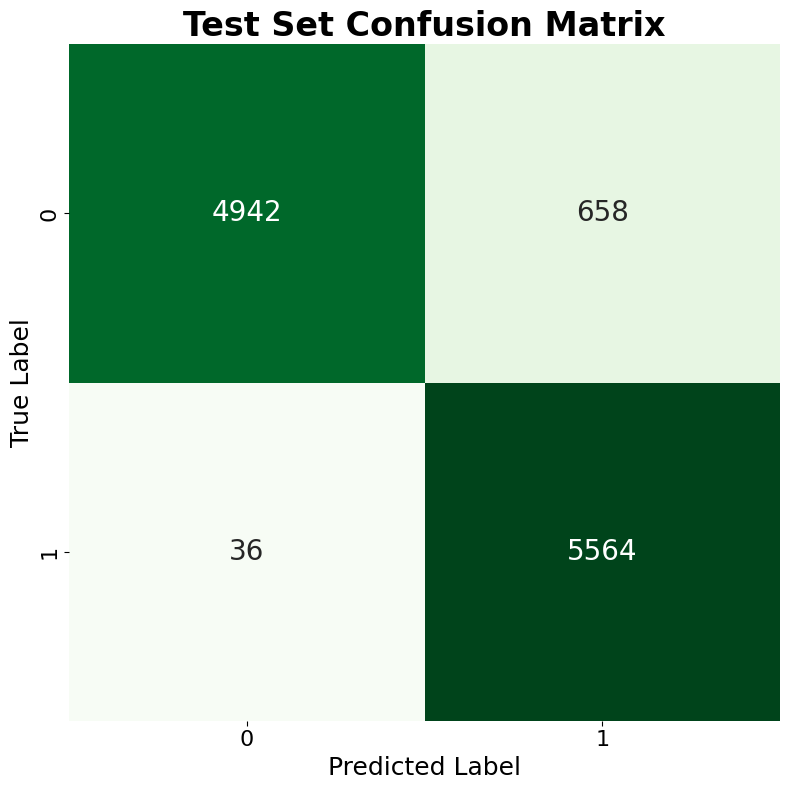

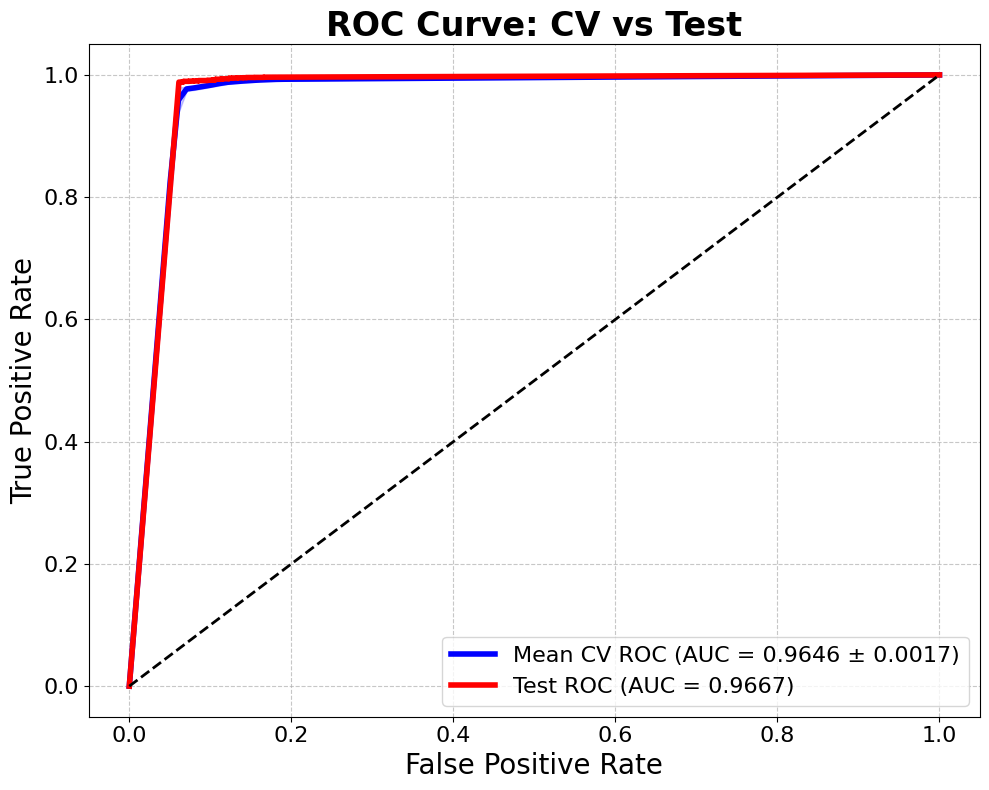

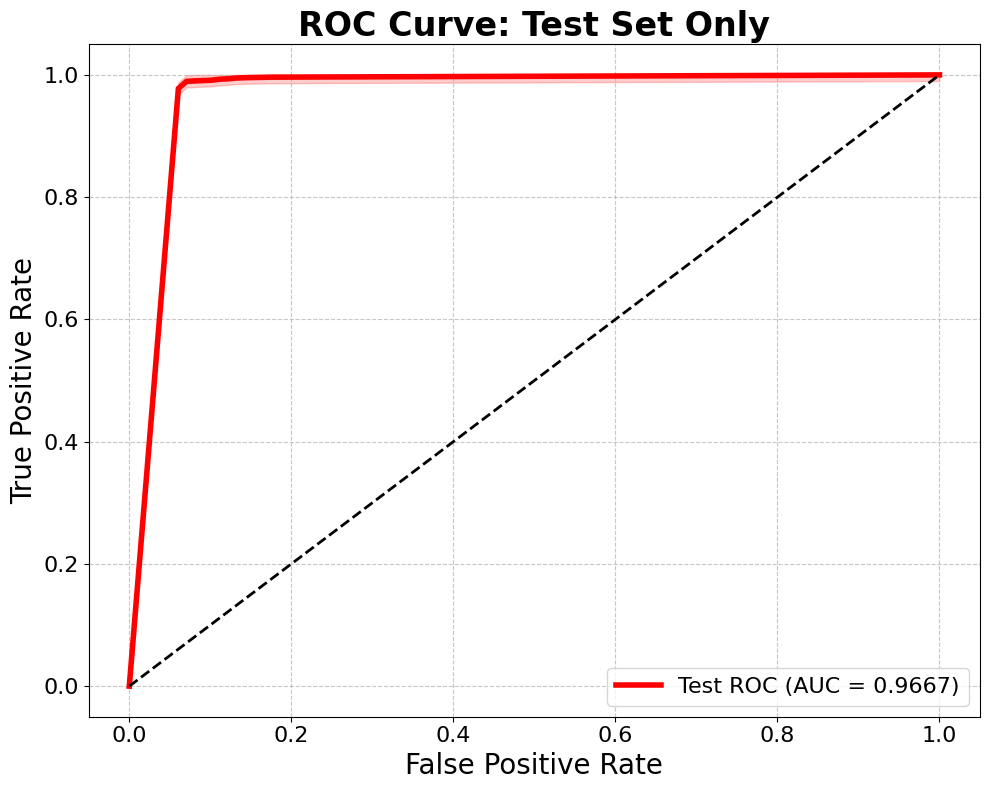


✅ Final KNN model saved as 'knn_tuned_10fold.pkl'


In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, classification_report,
                             confusion_matrix, roc_curve, auc)
import joblib
from collections import Counter

# === Assume X_train, y_train, X_test, y_test are pandas DataFrames/Series ===

param_grid = {
    'n_neighbors': [3, 5, 7],
    'weights': ['uniform', 'distance', 'uniform'],  # repeated 'uniform' to keep 3 options
    'metric': ['euclidean', 'manhattan', 'minkowski'],
    'p': [1, 2, 3],
    'leaf_size': [20, 30, 40]
}

skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

fold_metrics = []
fold_conf_matrices = []
tprs = []
roc_aucs = []
mean_fpr = np.linspace(0, 1, 100)
best_params_list = []

print("Starting 10-fold CV with RandomizedSearchCV tuning for KNN...\n")

for fold, (train_idx, val_idx) in enumerate(skf.split(X_train, y_train), 1):
    print(f"=== Fold {fold} ===")
    X_tr, X_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
    y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]

    knn = KNeighborsClassifier()

    rcv = RandomizedSearchCV(
        knn,
        param_distributions=param_grid,
        n_iter=15,
        scoring='accuracy',
        cv=3,
        n_jobs=-1,
        random_state=42,
        verbose=0
    )

    rcv.fit(X_tr, y_tr)
    best_knn = rcv.best_estimator_
    best_params_list.append(rcv.best_params_)

    y_pred = best_knn.predict(X_val)
    # For KNN, predict_proba may not be available if metric or algo chosen does not support it, but default supports it.
    y_prob = best_knn.predict_proba(X_val)[:, 1]

    acc = accuracy_score(y_val, y_pred)
    pre = precision_score(y_val, y_pred, average='weighted', zero_division=0)
    rec = recall_score(y_val, y_pred, average='weighted', zero_division=0)
    f1 = f1_score(y_val, y_pred, average='weighted', zero_division=0)
    roc = roc_auc_score(y_val, y_prob)

    fold_metrics.append((acc, pre, rec, f1, roc))

    print(f"Best params: {rcv.best_params_}")
    print(f"Accuracy:  {acc:.4f}")
    print(f"Precision: {pre:.4f}")
    print(f"Recall:    {rec:.4f}")
    print(f"F1-score:  {f1:.4f}")
    print(f"ROC AUC:   {roc:.4f}\n")

    cm = confusion_matrix(y_val, y_pred)
    fold_conf_matrices.append(cm)

    fpr, tpr, _ = roc_curve(y_val, y_prob)
    tprs.append(np.interp(mean_fpr, fpr, tpr))
    tprs[-1][0] = 0.0
    roc_aucs.append(roc)

metrics_array = np.array(fold_metrics)
metrics_names = ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC AUC']

print("=== Cross-validation Summary ===")
for i, metric_name in enumerate(metrics_names):
    mean_val = metrics_array[:, i].mean()
    std_val = metrics_array[:, i].std()
    print(f"{metric_name}: Mean = {mean_val:.4f}, Std = {std_val:.4f}")

sum_cm = np.sum(fold_conf_matrices, axis=0)

# CV Confusion Matrix (Greens)
plt.figure(figsize=(8, 8))
sns.heatmap(sum_cm, annot=True, fmt='d', cmap='Greens', cbar=False,
            annot_kws={"size": 20})
plt.title('Aggregated Confusion Matrix (CV)', fontsize=24, fontweight='bold')
plt.xlabel('Predicted Label', fontsize=18)
plt.ylabel('True Label', fontsize=18)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.tight_layout()
plt.show()

mean_tpr = np.mean(tprs, axis=0)
mean_tpr[-1] = 1.0
mean_auc = auc(mean_fpr, mean_tpr)
std_auc = np.std(roc_aucs)

tprs_upper = np.minimum(mean_tpr + np.std(tprs, axis=0), 1)
tprs_lower = np.maximum(mean_tpr - np.std(tprs, axis=0), 0)

plt.figure(figsize=(10, 8))
plt.plot(mean_fpr, mean_tpr, color='blue', lw=4,
         label=f'Mean CV ROC (AUC = {mean_auc:.4f} ± {std_auc:.4f})')
plt.fill_between(mean_fpr, tprs_lower, tprs_upper, color='blue', alpha=0.2)
plt.plot([0, 1], [0, 1], 'k--', lw=2)

plt.xlabel('False Positive Rate', fontsize=20)
plt.ylabel('True Positive Rate', fontsize=20)
plt.title('Mean ROC Curve with ±1 Std Dev (CV)', fontsize=24, fontweight='bold')
plt.legend(loc='lower right', fontsize=16)
plt.grid(alpha=0.7, linestyle='--')
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.tight_layout()
plt.show()

most_common_params = Counter(tuple(sorted(p.items())) for p in best_params_list).most_common(1)[0][0]
final_params = dict(most_common_params)

print("\nFinal hyperparameters selected:")
print(final_params)

final_model = KNeighborsClassifier(**final_params)
final_model.fit(X_train, y_train)

y_test_pred = final_model.predict(X_test)
y_test_prob = final_model.predict_proba(X_test)[:, 1]

acc = accuracy_score(y_test, y_test_pred)
pre = precision_score(y_test, y_test_pred, average='weighted', zero_division=0)
rec = recall_score(y_test, y_test_pred, average='weighted', zero_division=0)
f1 = f1_score(y_test, y_test_pred, average='weighted', zero_division=0)
roc_auc = roc_auc_score(y_test, y_test_prob)

print("\n=== Test Set Performance ===")
print(classification_report(y_test, y_test_pred))
print(f"Accuracy:  {acc:.4f}")
print(f"Precision: {pre:.4f}")
print(f"Recall:    {rec:.4f}")
print(f"F1-score:  {f1:.4f}")
print(f"ROC AUC:   {roc_auc:.4f}")

cm_test = confusion_matrix(y_test, y_test_pred)
plt.figure(figsize=(8, 8))
sns.heatmap(cm_test, annot=True, fmt='d', cmap='Greens', cbar=False,
            annot_kws={"size": 20})
plt.title('Test Set Confusion Matrix', fontsize=24, fontweight='bold')
plt.xlabel('Predicted Label', fontsize=18)
plt.ylabel('True Label', fontsize=18)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.tight_layout()
plt.show()

# Combined ROC: CV and Test
plt.figure(figsize=(10, 8))
plt.plot(mean_fpr, mean_tpr, color='blue', lw=4,
         label=f'Mean CV ROC (AUC = {mean_auc:.4f} ± {std_auc:.4f})')
plt.fill_between(mean_fpr, tprs_lower, tprs_upper, color='blue', alpha=0.2)

fpr_test, tpr_test, _ = roc_curve(y_test, y_test_prob)
plt.plot(fpr_test, tpr_test, color='red', lw=4,
         label=f'Test ROC (AUC = {roc_auc:.4f})')

plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlabel('False Positive Rate', fontsize=20)
plt.ylabel('True Positive Rate', fontsize=20)
plt.title('ROC Curve: CV vs Test', fontsize=24, fontweight='bold')
plt.legend(loc='lower right', fontsize=16)
plt.grid(alpha=0.7, linestyle='--')
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.tight_layout()
plt.show()

# Separate Test ROC (smoothed + shaded band)
mean_fpr_test = np.linspace(0, 1, 100)
interp_tpr_test = np.interp(mean_fpr_test, fpr_test, tpr_test)
interp_tpr_test[0] = 0.0
interp_tpr_test[-1] = 1.0

plt.figure(figsize=(10, 8))
plt.plot(mean_fpr_test, interp_tpr_test, color='red', lw=4,
         label=f'Test ROC (AUC = {roc_auc:.4f})')

plt.fill_between(mean_fpr_test,
                 np.maximum(interp_tpr_test - 0.01, 0),
                 np.minimum(interp_tpr_test + 0.01, 1),
                 color='red', alpha=0.2)

plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlabel('False Positive Rate', fontsize=20)
plt.ylabel('True Positive Rate', fontsize=20)
plt.title('ROC Curve: Test Set Only', fontsize=24, fontweight='bold')
plt.legend(loc='lower right', fontsize=16)
plt.grid(alpha=0.7, linestyle='--')
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.tight_layout()
plt.show()

# Save final model
joblib.dump(final_model, 'knn_tuned_10fold.pkl')
print("\n✅ Final KNN model saved as 'knn_tuned_10fold.pkl'")


# **ETC**

Starting 10-fold CV with RandomizedSearchCV tuning for Extra Trees Classifier...

=== Fold 1 ===
Best params: {'n_estimators': 200, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_depth': 18, 'bootstrap': True}
Accuracy:  0.9342
Precision: 0.9385
Recall:    0.9342
F1-score:  0.9340
ROC AUC:   0.9884

=== Fold 2 ===
Best params: {'n_estimators': 200, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_depth': 18, 'bootstrap': True}
Accuracy:  0.9292
Precision: 0.9335
Recall:    0.9292
F1-score:  0.9291
ROC AUC:   0.9867

=== Fold 3 ===
Best params: {'n_estimators': 200, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_depth': 18, 'bootstrap': True}
Accuracy:  0.9333
Precision: 0.9387
Recall:    0.9333
F1-score:  0.9331
ROC AUC:   0.9881

=== Fold 4 ===
Best params: {'n_estimators': 200, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_depth': 18, 'bootstrap': True}
Accuracy:  0.9339
Precision: 0.9373
Recall:    0.9339
F1-score:  0.9338
ROC AUC:   0.9883

=== Fold 5 ===
Best pa

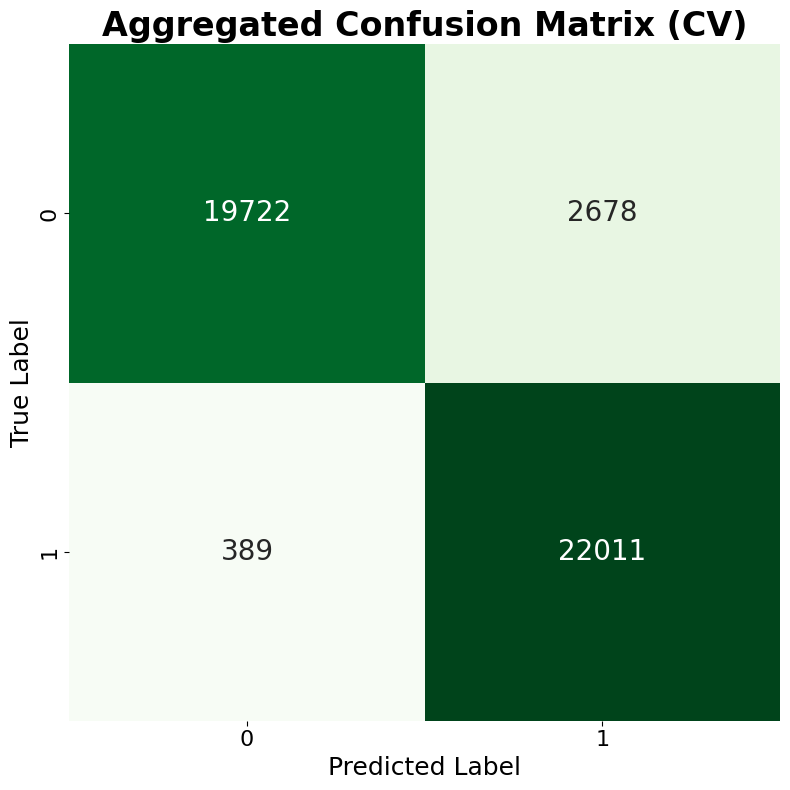

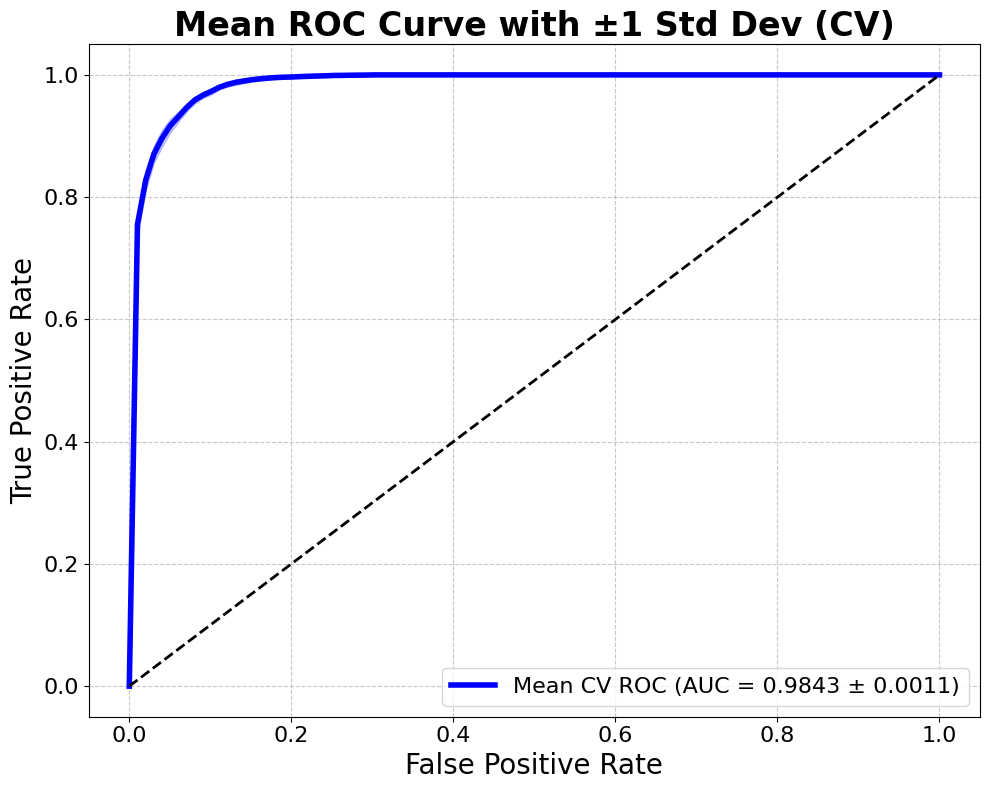


Final hyperparameters selected:
{'bootstrap': True, 'max_depth': 18, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200}

=== Test Set Performance ===
              precision    recall  f1-score   support

         0.0       0.99      0.88      0.93      5600
         1.0       0.89      0.99      0.94      5600

    accuracy                           0.93     11200
   macro avg       0.94      0.93      0.93     11200
weighted avg       0.94      0.93      0.93     11200

Accuracy:  0.9340
Precision: 0.9389
Recall:    0.9340
F1-score:  0.9338
ROC AUC:   0.9880


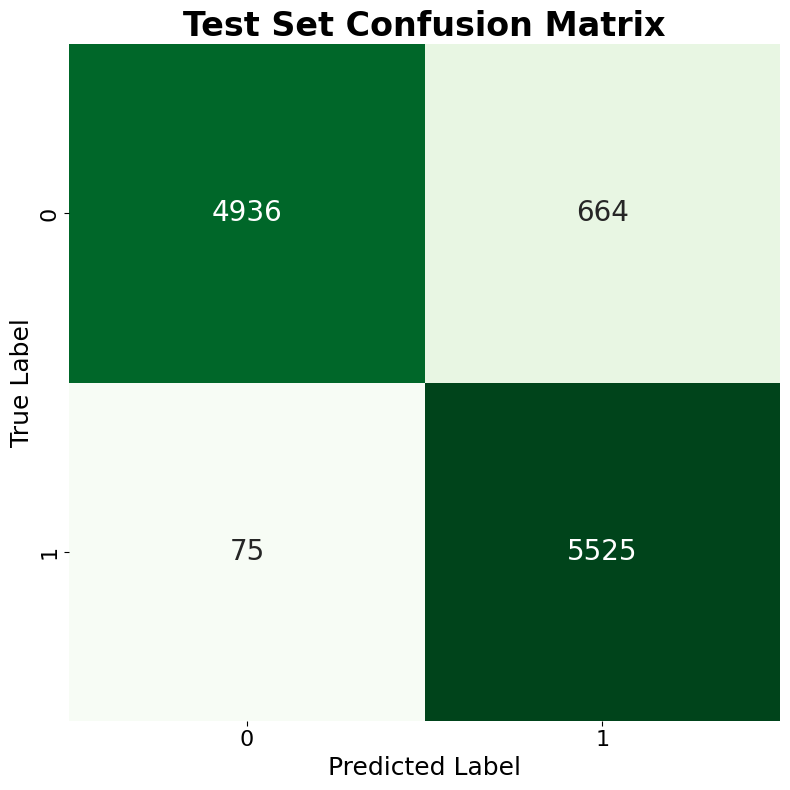

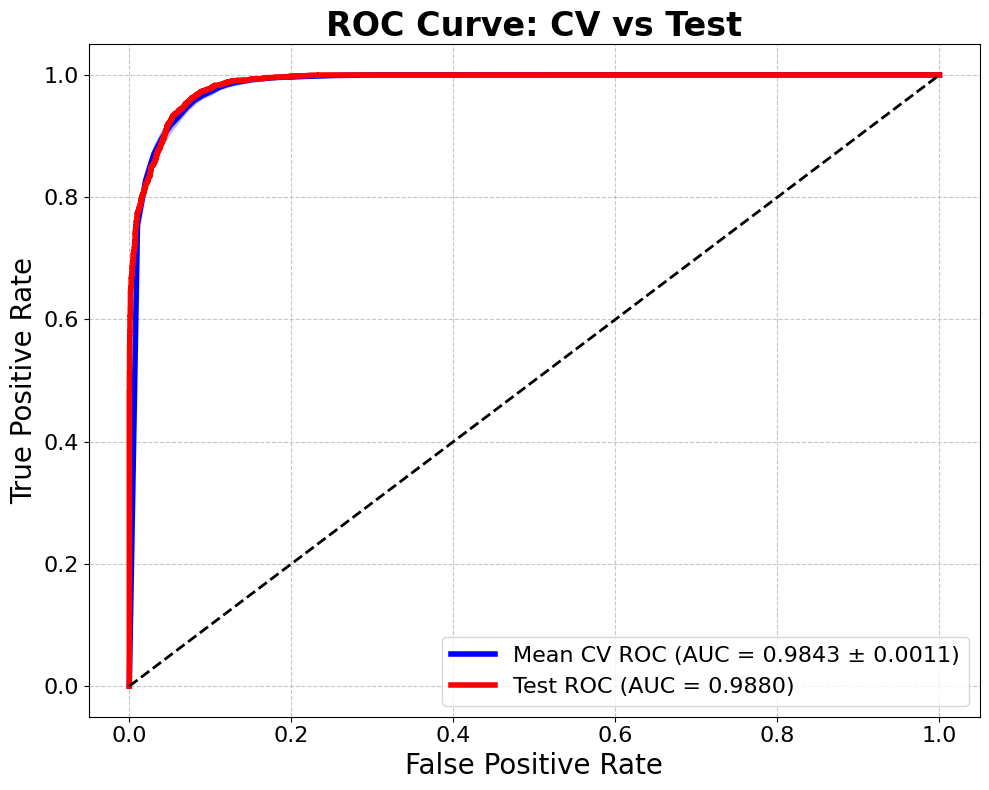

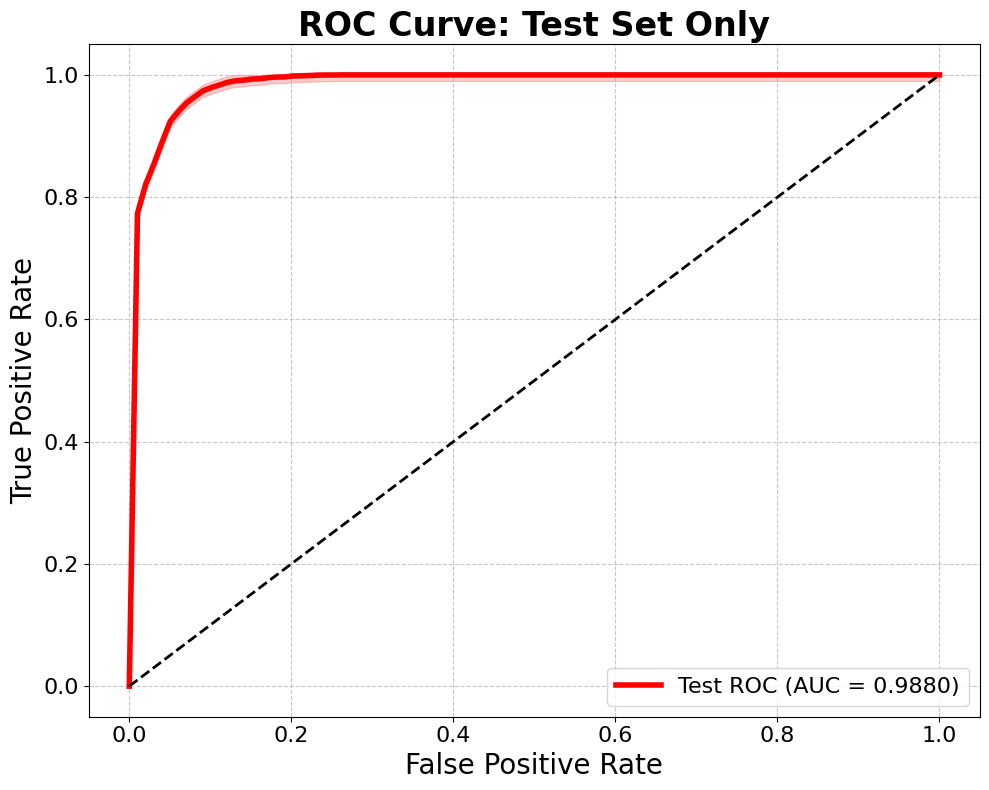


✅ Final Extra Trees model saved as 'extra_trees_tuned_10fold.pkl'


In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import ExtraTreesClassifier
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, classification_report,
                             confusion_matrix, roc_curve, auc)
import joblib
from collections import Counter

# === Assume X_train, y_train, X_test, y_test are pandas DataFrames/Series ===

param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [6, 12, 18],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'bootstrap': [True, False]
}

skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

fold_metrics = []
fold_conf_matrices = []
tprs = []
roc_aucs = []
mean_fpr = np.linspace(0, 1, 100)
best_params_list = []

print("Starting 10-fold CV with RandomizedSearchCV tuning for Extra Trees Classifier...\n")

for fold, (train_idx, val_idx) in enumerate(skf.split(X_train, y_train), 1):
    print(f"=== Fold {fold} ===")
    X_tr, X_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
    y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]

    etc = ExtraTreesClassifier(random_state=42, n_jobs=-1)

    rcv = RandomizedSearchCV(
        etc,
        param_distributions=param_grid,
        n_iter=15,
        scoring='accuracy',
        cv=3,
        n_jobs=-1,
        random_state=42,
        verbose=0
    )

    rcv.fit(X_tr, y_tr)
    best_etc = rcv.best_estimator_
    best_params_list.append(rcv.best_params_)

    y_pred = best_etc.predict(X_val)
    y_prob = best_etc.predict_proba(X_val)[:, 1]

    acc = accuracy_score(y_val, y_pred)
    pre = precision_score(y_val, y_pred, average='weighted', zero_division=0)
    rec = recall_score(y_val, y_pred, average='weighted', zero_division=0)
    f1 = f1_score(y_val, y_pred, average='weighted', zero_division=0)
    roc = roc_auc_score(y_val, y_prob)

    fold_metrics.append((acc, pre, rec, f1, roc))

    print(f"Best params: {rcv.best_params_}")
    print(f"Accuracy:  {acc:.4f}")
    print(f"Precision: {pre:.4f}")
    print(f"Recall:    {rec:.4f}")
    print(f"F1-score:  {f1:.4f}")
    print(f"ROC AUC:   {roc:.4f}\n")

    cm = confusion_matrix(y_val, y_pred)
    fold_conf_matrices.append(cm)

    fpr, tpr, _ = roc_curve(y_val, y_prob)
    tprs.append(np.interp(mean_fpr, fpr, tpr))
    tprs[-1][0] = 0.0
    roc_aucs.append(roc)

metrics_array = np.array(fold_metrics)
metrics_names = ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC AUC']

print("=== Cross-validation Summary ===")
for i, metric_name in enumerate(metrics_names):
    mean_val = metrics_array[:, i].mean()
    std_val = metrics_array[:, i].std()
    print(f"{metric_name}: Mean = {mean_val:.4f}, Std = {std_val:.4f}")

sum_cm = np.sum(fold_conf_matrices, axis=0)

# CV Confusion Matrix (Greens)
plt.figure(figsize=(8, 8))
sns.heatmap(sum_cm, annot=True, fmt='d', cmap='Greens', cbar=False,
            annot_kws={"size": 20})
plt.title('Aggregated Confusion Matrix (CV)', fontsize=24, fontweight='bold')
plt.xlabel('Predicted Label', fontsize=18)
plt.ylabel('True Label', fontsize=18)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.tight_layout()
plt.show()

mean_tpr = np.mean(tprs, axis=0)
mean_tpr[-1] = 1.0
mean_auc = auc(mean_fpr, mean_tpr)
std_auc = np.std(roc_aucs)

tprs_upper = np.minimum(mean_tpr + np.std(tprs, axis=0), 1)
tprs_lower = np.maximum(mean_tpr - np.std(tprs, axis=0), 0)

plt.figure(figsize=(10, 8))
plt.plot(mean_fpr, mean_tpr, color='blue', lw=4,
         label=f'Mean CV ROC (AUC = {mean_auc:.4f} ± {std_auc:.4f})')
plt.fill_between(mean_fpr, tprs_lower, tprs_upper, color='blue', alpha=0.2)
plt.plot([0, 1], [0, 1], 'k--', lw=2)

plt.xlabel('False Positive Rate', fontsize=20)
plt.ylabel('True Positive Rate', fontsize=20)
plt.title('Mean ROC Curve with ±1 Std Dev (CV)', fontsize=24, fontweight='bold')
plt.legend(loc='lower right', fontsize=16)
plt.grid(alpha=0.7, linestyle='--')
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.tight_layout()
plt.show()

most_common_params = Counter(tuple(sorted(p.items())) for p in best_params_list).most_common(1)[0][0]
final_params = dict(most_common_params)

print("\nFinal hyperparameters selected:")
print(final_params)

final_model = ExtraTreesClassifier(random_state=42, n_jobs=-1, **final_params)
final_model.fit(X_train, y_train)

y_test_pred = final_model.predict(X_test)
y_test_prob = final_model.predict_proba(X_test)[:, 1]

acc = accuracy_score(y_test, y_test_pred)
pre = precision_score(y_test, y_test_pred, average='weighted', zero_division=0)
rec = recall_score(y_test, y_test_pred, average='weighted', zero_division=0)
f1 = f1_score(y_test, y_test_pred, average='weighted', zero_division=0)
roc_auc = roc_auc_score(y_test, y_test_prob)

print("\n=== Test Set Performance ===")
print(classification_report(y_test, y_test_pred))
print(f"Accuracy:  {acc:.4f}")
print(f"Precision: {pre:.4f}")
print(f"Recall:    {rec:.4f}")
print(f"F1-score:  {f1:.4f}")
print(f"ROC AUC:   {roc_auc:.4f}")

cm_test = confusion_matrix(y_test, y_test_pred)
plt.figure(figsize=(8, 8))
sns.heatmap(cm_test, annot=True, fmt='d', cmap='Greens', cbar=False,
            annot_kws={"size": 20})
plt.title('Test Set Confusion Matrix', fontsize=24, fontweight='bold')
plt.xlabel('Predicted Label', fontsize=18)
plt.ylabel('True Label', fontsize=18)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.tight_layout()
plt.show()

# Combined ROC: CV and Test
plt.figure(figsize=(10, 8))
plt.plot(mean_fpr, mean_tpr, color='blue', lw=4,
         label=f'Mean CV ROC (AUC = {mean_auc:.4f} ± {std_auc:.4f})')
plt.fill_between(mean_fpr, tprs_lower, tprs_upper, color='blue', alpha=0.2)

fpr_test, tpr_test, _ = roc_curve(y_test, y_test_prob)
plt.plot(fpr_test, tpr_test, color='red', lw=4,
         label=f'Test ROC (AUC = {roc_auc:.4f})')

plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlabel('False Positive Rate', fontsize=20)
plt.ylabel('True Positive Rate', fontsize=20)
plt.title('ROC Curve: CV vs Test', fontsize=24, fontweight='bold')
plt.legend(loc='lower right', fontsize=16)
plt.grid(alpha=0.7, linestyle='--')
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.tight_layout()
plt.show()

# Separate Test ROC (smoothed + shaded band)
mean_fpr_test = np.linspace(0, 1, 100)
interp_tpr_test = np.interp(mean_fpr_test, fpr_test, tpr_test)
interp_tpr_test[0] = 0.0
interp_tpr_test[-1] = 1.0

plt.figure(figsize=(10, 8))
plt.plot(mean_fpr_test, interp_tpr_test, color='red', lw=4,
         label=f'Test ROC (AUC = {roc_auc:.4f})')

plt.fill_between(mean_fpr_test,
                 np.maximum(interp_tpr_test - 0.01, 0),
                 np.minimum(interp_tpr_test + 0.01, 1),
                 color='red', alpha=0.2)

plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlabel('False Positive Rate', fontsize=20)
plt.ylabel('True Positive Rate', fontsize=20)
plt.title('ROC Curve: Test Set Only', fontsize=24, fontweight='bold')
plt.legend(loc='lower right', fontsize=16)
plt.grid(alpha=0.7, linestyle='--')
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.tight_layout()
plt.show()

# Save final model
joblib.dump(final_model, 'extra_trees_tuned_10fold.pkl')
print("\n✅ Final Extra Trees model saved as 'extra_trees_tuned_10fold.pkl'")


# **RF ETC**

Starting 10-fold CV for stacking ensemble...

=== Fold 1 ===
Tuning RandomForest...
RF best params: {'n_estimators': 50, 'min_samples_split': 2, 'min_samples_leaf': 2, 'max_depth': 18, 'bootstrap': False}
Tuning ExtraTrees...
ETC best params: {'n_estimators': 100, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_depth': 18, 'bootstrap': True}
Tuning meta LogisticRegression inside stacking...
Best meta params: {'final_estimator__solver': 'saga', 'final_estimator__penalty': 'l1', 'final_estimator__C': 0.01}
Accuracy:  0.9647
Precision: 0.9649
Recall:    0.9647
F1-score:  0.9647
ROC AUC:   0.9949

=== Fold 2 ===
Tuning RandomForest...
RF best params: {'n_estimators': 50, 'min_samples_split': 2, 'min_samples_leaf': 2, 'max_depth': 18, 'bootstrap': False}
Tuning ExtraTrees...
ETC best params: {'n_estimators': 100, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_depth': 18, 'bootstrap': True}
Tuning meta LogisticRegression inside stacking...
Best meta params: {'final_estimator__solver

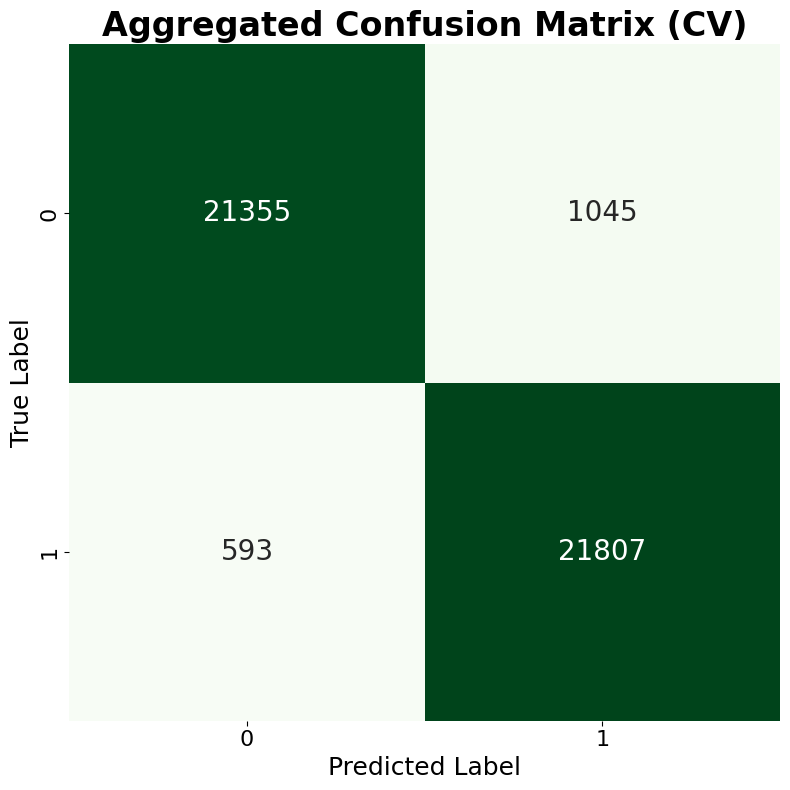

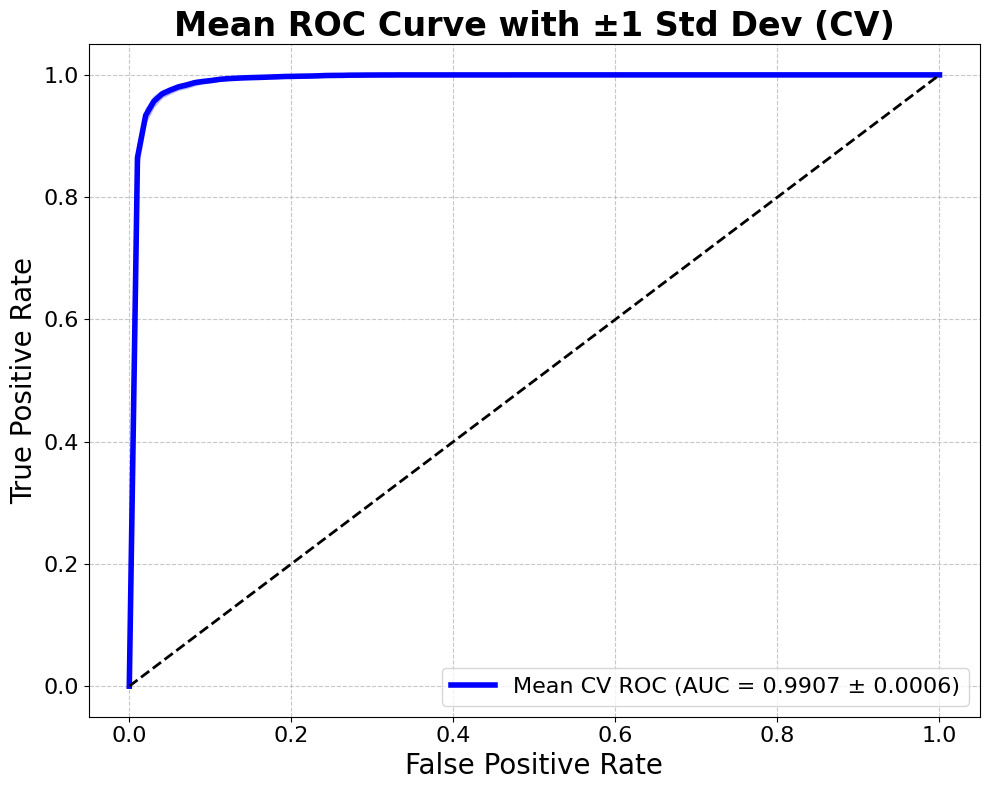


Training final stacking model on full training data...
Final RF params: {'n_estimators': 50, 'min_samples_split': 2, 'min_samples_leaf': 2, 'max_depth': 18, 'bootstrap': False}
Final ETC params: {'n_estimators': 100, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_depth': 18, 'bootstrap': True}
Final meta params: {'final_estimator__solver': 'saga', 'final_estimator__penalty': 'l1', 'final_estimator__C': 0.01}

=== Test Set Performance ===
              precision    recall  f1-score   support

         0.0       0.98      0.96      0.97      5600
         1.0       0.96      0.98      0.97      5600

    accuracy                           0.97     11200
   macro avg       0.97      0.97      0.97     11200
weighted avg       0.97      0.97      0.97     11200

Accuracy:  0.9679
Precision: 0.9681
Recall:    0.9679
F1-score:  0.9679
ROC AUC:   0.9956


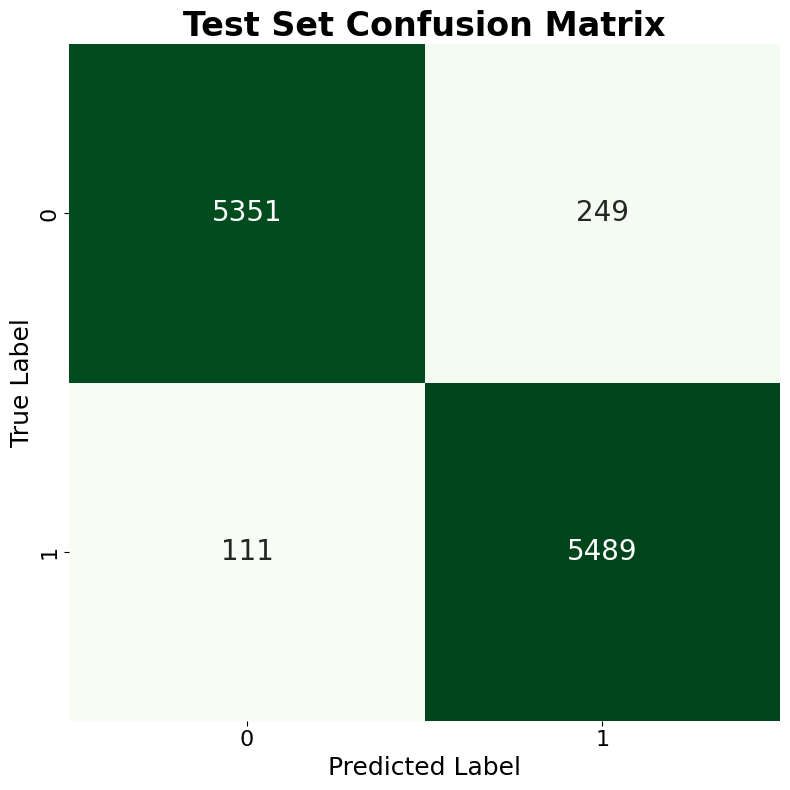

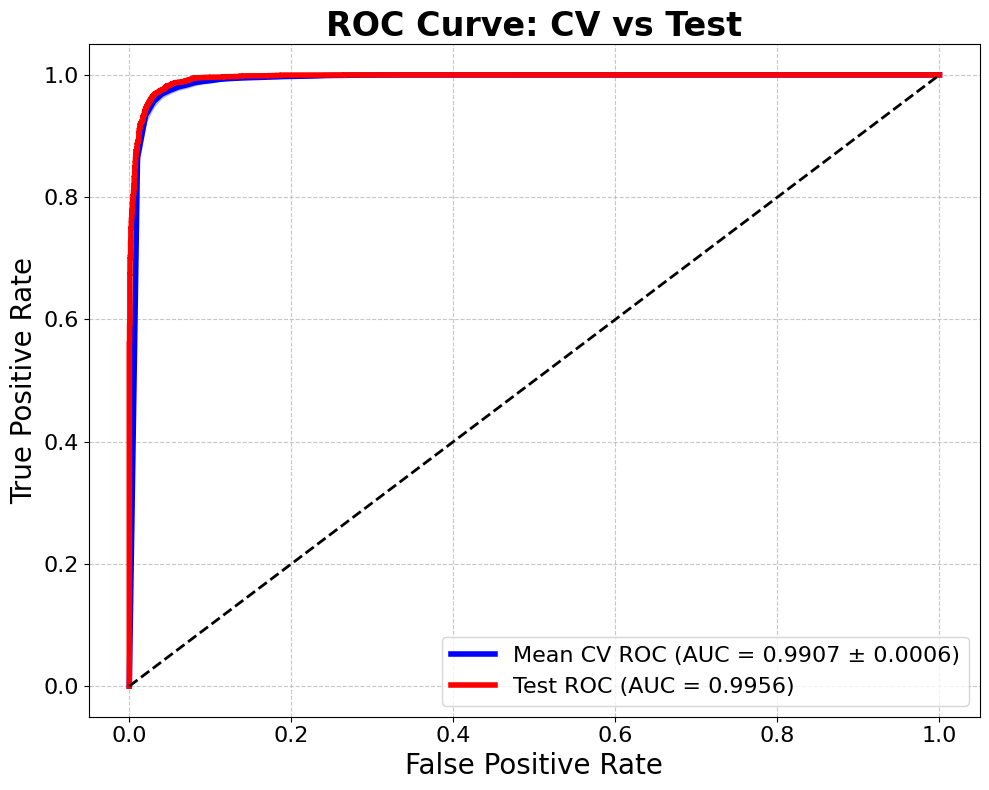

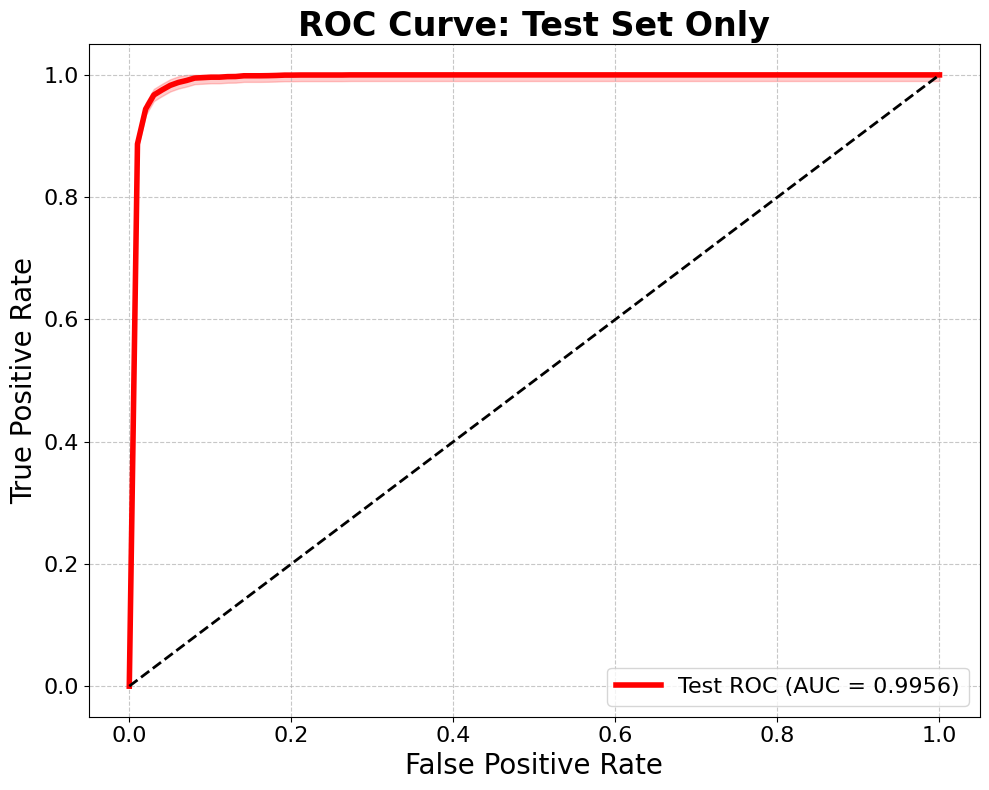


✅ Final stacking ensemble model saved as 'stacking_ensemble_rf_etc_lr.pkl'


In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, classification_report,
                             confusion_matrix, roc_curve, auc)
import joblib
from collections import Counter

# === Assume X_train, y_train, X_test, y_test are defined ===

# Hyperparameter grids for base models
param_grid_rf = {
    'n_estimators': [50, 100, 150],
    'max_depth': [6, 12, 18],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'bootstrap': [True, False]
}

param_grid_etc = {
    'n_estimators': [50, 100, 150],
    'max_depth': [6, 12, 18],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'bootstrap': [True, False]
}

# Hyperparameter grid for meta model (LogisticRegression)
param_grid_meta = {
    'C': [0.01, 0.1, 1],
    'penalty': ['l1', 'l2', 'elasticnet'],
    'solver': ['saga', 'liblinear', 'saga']  # saga twice to allow elasticnet penalty
}

# Function to tune a base estimator with RandomizedSearchCV on training fold
def tune_base_model(model, param_grid, X_tr, y_tr):
    rcv = RandomizedSearchCV(
        model,
        param_distributions=param_grid,
        n_iter=15,
        scoring='accuracy',
        cv=3,
        n_jobs=-1,
        random_state=42,
        verbose=0
    )
    rcv.fit(X_tr, y_tr)
    return rcv.best_estimator_, rcv.best_params_

# Tune meta model within stacking, so param tuning on meta will be done later with RandomizedSearchCV

skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

fold_metrics = []
fold_conf_matrices = []
tprs = []
roc_aucs = []
mean_fpr = np.linspace(0, 1, 100)

print("Starting 10-fold CV for stacking ensemble...\n")

for fold, (train_idx, val_idx) in enumerate(skf.split(X_train, y_train), 1):
    print(f"=== Fold {fold} ===")
    X_tr, X_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
    y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]

    # Tune base estimators on training fold
    print("Tuning RandomForest...")
    best_rf, best_rf_params = tune_base_model(RandomForestClassifier(random_state=42), param_grid_rf, X_tr, y_tr)
    print(f"RF best params: {best_rf_params}")

    print("Tuning ExtraTrees...")
    best_etc, best_etc_params = tune_base_model(ExtraTreesClassifier(random_state=42), param_grid_etc, X_tr, y_tr)
    print(f"ETC best params: {best_etc_params}")

    # Define stacking with tuned base estimators (frozen params)
    base_estimators = [
        ('rf', best_rf),
        ('etc', best_etc)
    ]

    # Meta model — Logistic Regression (tune separately on fold training)
    meta_lr = LogisticRegression(random_state=42, max_iter=1000)

    # Define stacking classifier
    stacking_clf = StackingClassifier(
        estimators=base_estimators,
        final_estimator=meta_lr,
        cv=3,
        n_jobs=-1,
        passthrough=False,
        verbose=0
    )

    # Tune meta model parameters using RandomizedSearchCV on X_tr,y_tr with stacking fixed base
    print("Tuning meta LogisticRegression inside stacking...")
    meta_rcv = RandomizedSearchCV(
        stacking_clf,
        param_distributions={
            'final_estimator__C': param_grid_meta['C'],
            'final_estimator__penalty': param_grid_meta['penalty'],
            'final_estimator__solver': param_grid_meta['solver'],
        },
        n_iter=15,
        scoring='accuracy',
        cv=3,
        n_jobs=-1,
        random_state=42,
        verbose=0
    )

    meta_rcv.fit(X_tr, y_tr)
    best_stacking = meta_rcv.best_estimator_

    print(f"Best meta params: {meta_rcv.best_params_}")

    # Predict on validation fold
    y_pred = best_stacking.predict(X_val)
    y_prob = best_stacking.predict_proba(X_val)[:, 1]

    acc = accuracy_score(y_val, y_pred)
    pre = precision_score(y_val, y_pred, average='weighted', zero_division=0)
    rec = recall_score(y_val, y_pred, average='weighted', zero_division=0)
    f1 = f1_score(y_val, y_pred, average='weighted', zero_division=0)
    roc = roc_auc_score(y_val, y_prob)

    fold_metrics.append((acc, pre, rec, f1, roc))

    print(f"Accuracy:  {acc:.4f}")
    print(f"Precision: {pre:.4f}")
    print(f"Recall:    {rec:.4f}")
    print(f"F1-score:  {f1:.4f}")
    print(f"ROC AUC:   {roc:.4f}\n")

    cm = confusion_matrix(y_val, y_pred)
    fold_conf_matrices.append(cm)

    fpr, tpr, _ = roc_curve(y_val, y_prob)
    tprs.append(np.interp(mean_fpr, fpr, tpr))
    tprs[-1][0] = 0.0
    roc_aucs.append(roc)

# CV metrics summary
metrics_array = np.array(fold_metrics)
metrics_names = ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC AUC']

print("=== Cross-validation Summary ===")
for i, metric_name in enumerate(metrics_names):
    mean_val = metrics_array[:, i].mean()
    std_val = metrics_array[:, i].std()
    print(f"{metric_name}: Mean = {mean_val:.4f}, Std = {std_val:.4f}")

sum_cm = np.sum(fold_conf_matrices, axis=0)

plt.figure(figsize=(8, 8))
sns.heatmap(sum_cm, annot=True, fmt='d', cmap='Greens', cbar=False,
            annot_kws={"size": 20})
plt.title('Aggregated Confusion Matrix (CV)', fontsize=24, fontweight='bold')
plt.xlabel('Predicted Label', fontsize=18)
plt.ylabel('True Label', fontsize=18)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.tight_layout()
plt.show()

mean_tpr = np.mean(tprs, axis=0)
mean_tpr[-1] = 1.0
mean_auc = auc(mean_fpr, mean_tpr)
std_auc = np.std(roc_aucs)

tprs_upper = np.minimum(mean_tpr + np.std(tprs, axis=0), 1)
tprs_lower = np.maximum(mean_tpr - np.std(tprs, axis=0), 0)

plt.figure(figsize=(10, 8))
plt.plot(mean_fpr, mean_tpr, color='blue', lw=4,
         label=f'Mean CV ROC (AUC = {mean_auc:.4f} ± {std_auc:.4f})')
plt.fill_between(mean_fpr, tprs_lower, tprs_upper, color='blue', alpha=0.2)
plt.plot([0, 1], [0, 1], 'k--', lw=2)

plt.xlabel('False Positive Rate', fontsize=20)
plt.ylabel('True Positive Rate', fontsize=20)
plt.title('Mean ROC Curve with ±1 Std Dev (CV)', fontsize=24, fontweight='bold')
plt.legend(loc='lower right', fontsize=16)
plt.grid(alpha=0.7, linestyle='--')
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.tight_layout()
plt.show()

# Final model training on full data:

print("\nTraining final stacking model on full training data...")

# Tune base estimators on full training set
final_rf, final_rf_params = tune_base_model(RandomForestClassifier(random_state=42), param_grid_rf, X_train, y_train)
final_etc, final_etc_params = tune_base_model(ExtraTreesClassifier(random_state=42), param_grid_etc, X_train, y_train)

print(f"Final RF params: {final_rf_params}")
print(f"Final ETC params: {final_etc_params}")

base_estimators_final = [
    ('rf', final_rf),
    ('etc', final_etc)
]

# Stacking with unfitted meta (will tune meta next)
stacking_final = StackingClassifier(
    estimators=base_estimators_final,
    final_estimator=LogisticRegression(random_state=42, max_iter=1000),
    cv=3,
    n_jobs=-1,
    passthrough=False,
    verbose=0
)

# Tune meta parameters on full training data
meta_rcv_final = RandomizedSearchCV(
    stacking_final,
    param_distributions={
        'final_estimator__C': param_grid_meta['C'],
        'final_estimator__penalty': param_grid_meta['penalty'],
        'final_estimator__solver': param_grid_meta['solver'],
    },
    n_iter=15,
    scoring='accuracy',
    cv=3,
    n_jobs=-1,
    random_state=42,
    verbose=0
)

meta_rcv_final.fit(X_train, y_train)
final_model = meta_rcv_final.best_estimator_

print(f"Final meta params: {meta_rcv_final.best_params_}")

# Test set evaluation
y_test_pred = final_model.predict(X_test)
y_test_prob = final_model.predict_proba(X_test)[:, 1]

acc = accuracy_score(y_test, y_test_pred)
pre = precision_score(y_test, y_test_pred, average='weighted', zero_division=0)
rec = recall_score(y_test, y_test_pred, average='weighted', zero_division=0)
f1 = f1_score(y_test, y_test_pred, average='weighted', zero_division=0)
roc_auc = roc_auc_score(y_test, y_test_prob)

print("\n=== Test Set Performance ===")
print(classification_report(y_test, y_test_pred))
print(f"Accuracy:  {acc:.4f}")
print(f"Precision: {pre:.4f}")
print(f"Recall:    {rec:.4f}")
print(f"F1-score:  {f1:.4f}")
print(f"ROC AUC:   {roc_auc:.4f}")

cm_test = confusion_matrix(y_test, y_test_pred)
plt.figure(figsize=(8, 8))
sns.heatmap(cm_test, annot=True, fmt='d', cmap='Greens', cbar=False,
            annot_kws={"size": 20})
plt.title('Test Set Confusion Matrix', fontsize=24, fontweight='bold')
plt.xlabel('Predicted Label', fontsize=18)
plt.ylabel('True Label', fontsize=18)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.tight_layout()
plt.show()

# Plot ROC curves for CV mean and test (same style)

plt.figure(figsize=(10, 8))
plt.plot(mean_fpr, mean_tpr, color='blue', lw=4,
         label=f'Mean CV ROC (AUC = {mean_auc:.4f} ± {std_auc:.4f})')
plt.fill_between(mean_fpr, tprs_lower, tprs_upper, color='blue', alpha=0.2)

fpr_test, tpr_test, _ = roc_curve(y_test, y_test_prob)
plt.plot(fpr_test, tpr_test, color='red', lw=4,
         label=f'Test ROC (AUC = {roc_auc:.4f})')

plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlabel('False Positive Rate', fontsize=20)
plt.ylabel('True Positive Rate', fontsize=20)
plt.title('ROC Curve: CV vs Test', fontsize=24, fontweight='bold')
plt.legend(loc='lower right', fontsize=16)
plt.grid(alpha=0.7, linestyle='--')
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.tight_layout()
plt.show()

# Separate Test ROC plot with same style
mean_fpr_test = np.linspace(0, 1, 100)
interp_tpr_test = np.interp(mean_fpr_test, fpr_test, tpr_test)
interp_tpr_test[0] = 0.0
interp_tpr_test[-1] = 1.0

plt.figure(figsize=(10, 8))
plt.plot(mean_fpr_test, interp_tpr_test, color='red', lw=4,
         label=f'Test ROC (AUC = {roc_auc:.4f})')

plt.fill_between(mean_fpr_test,
                 np.maximum(interp_tpr_test - 0.01, 0),
                 np.minimum(interp_tpr_test + 0.01, 1),
                 color='red', alpha=0.2)

plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlabel('False Positive Rate', fontsize=20)
plt.ylabel('True Positive Rate', fontsize=20)
plt.title('ROC Curve: Test Set Only', fontsize=24, fontweight='bold')
plt.legend(loc='lower right', fontsize=16)
plt.grid(alpha=0.7, linestyle='--')
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.tight_layout()
plt.show()

# Save final stacking model
joblib.dump(final_model, 'stacking_ensemble_rf_etc_lr.pkl')
print("\n✅ Final stacking ensemble model saved as 'stacking_ensemble_rf_etc_lr.pkl'")


# **KNN ETC**

Starting 10-fold CV for stacking ensemble with KNN + ETC...

=== Fold 1 ===
Tuning KNN...
KNN best params: {'weights': 'distance', 'p': 1, 'n_neighbors': 3, 'leaf_size': 20, 'algorithm': 'ball_tree'}
Tuning ExtraTrees...
ETC best params: {'n_estimators': 100, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_depth': 18, 'bootstrap': True}
Tuning meta LogisticRegression inside stacking...
Best meta params: {'final_estimator__solver': 'saga', 'final_estimator__penalty': 'l2', 'final_estimator__C': 0.1}
Accuracy:  0.9571
Precision: 0.9584
Recall:    0.9571
F1-score:  0.9571
ROC AUC:   0.9918

=== Fold 2 ===
Tuning KNN...
KNN best params: {'weights': 'distance', 'p': 1, 'n_neighbors': 3, 'leaf_size': 20, 'algorithm': 'ball_tree'}
Tuning ExtraTrees...
ETC best params: {'n_estimators': 100, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_depth': 18, 'bootstrap': True}
Tuning meta LogisticRegression inside stacking...
Best meta params: {'final_estimator__solver': 'saga', 'final_estimato

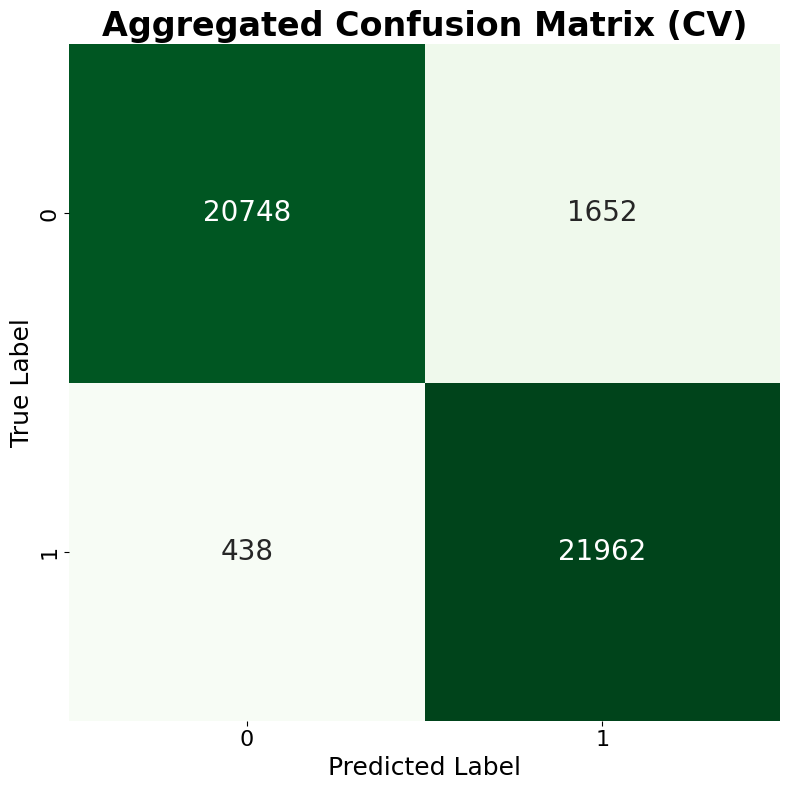

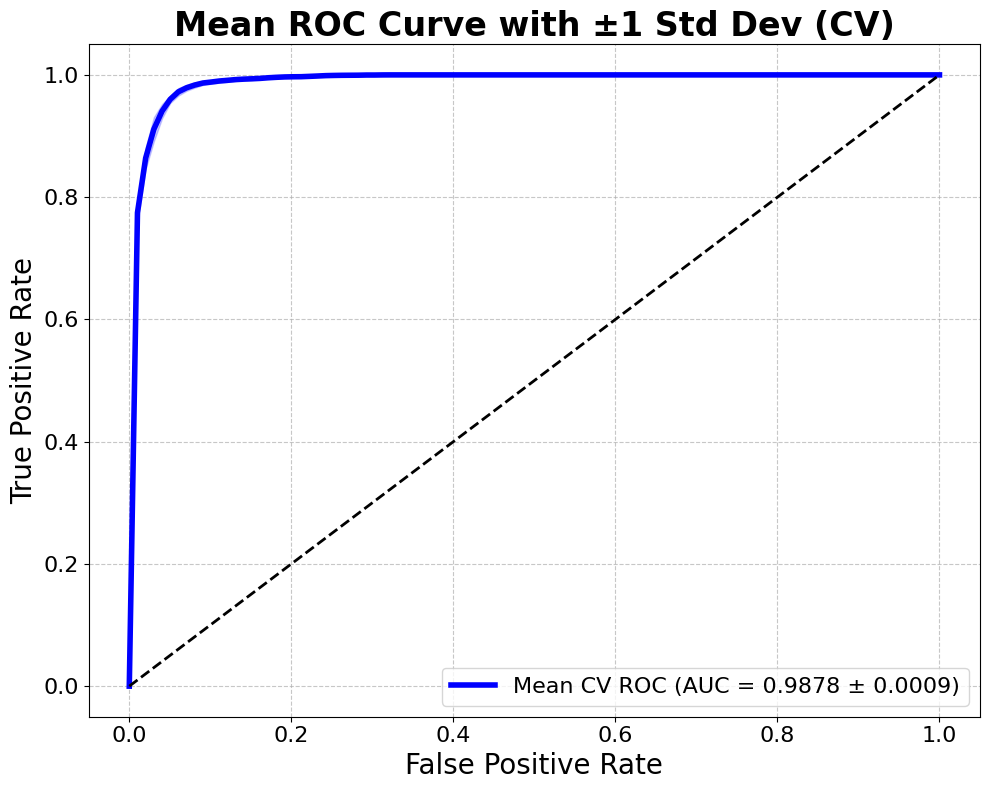


Training final stacking model on full training data...
Final KNN params: {'weights': 'distance', 'p': 1, 'n_neighbors': 3, 'leaf_size': 20, 'algorithm': 'ball_tree'}
Final ETC params: {'n_estimators': 100, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_depth': 18, 'bootstrap': True}
Final meta params: {'final_estimator__solver': 'saga', 'final_estimator__penalty': 'l2', 'final_estimator__C': 0.1}

=== Test Set Performance ===
              precision    recall  f1-score   support

         0.0       0.99      0.93      0.96      5600
         1.0       0.93      0.99      0.96      5600

    accuracy                           0.96     11200
   macro avg       0.96      0.96      0.96     11200
weighted avg       0.96      0.96      0.96     11200

Accuracy:  0.9586
Precision: 0.9600
Recall:    0.9586
F1-score:  0.9585
ROC AUC:   0.9921


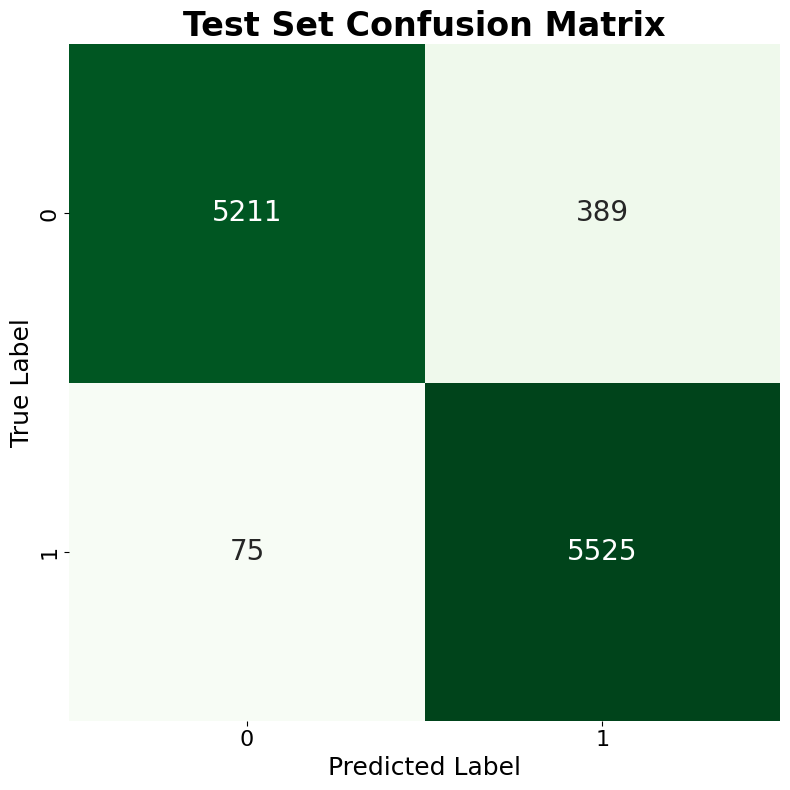

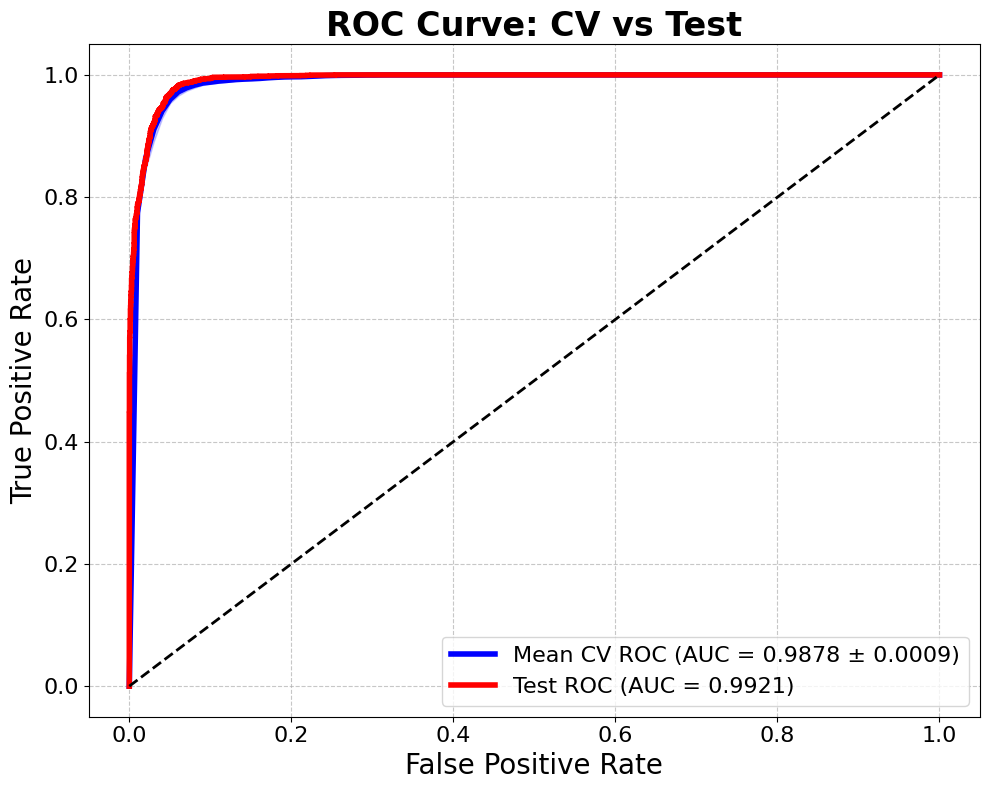

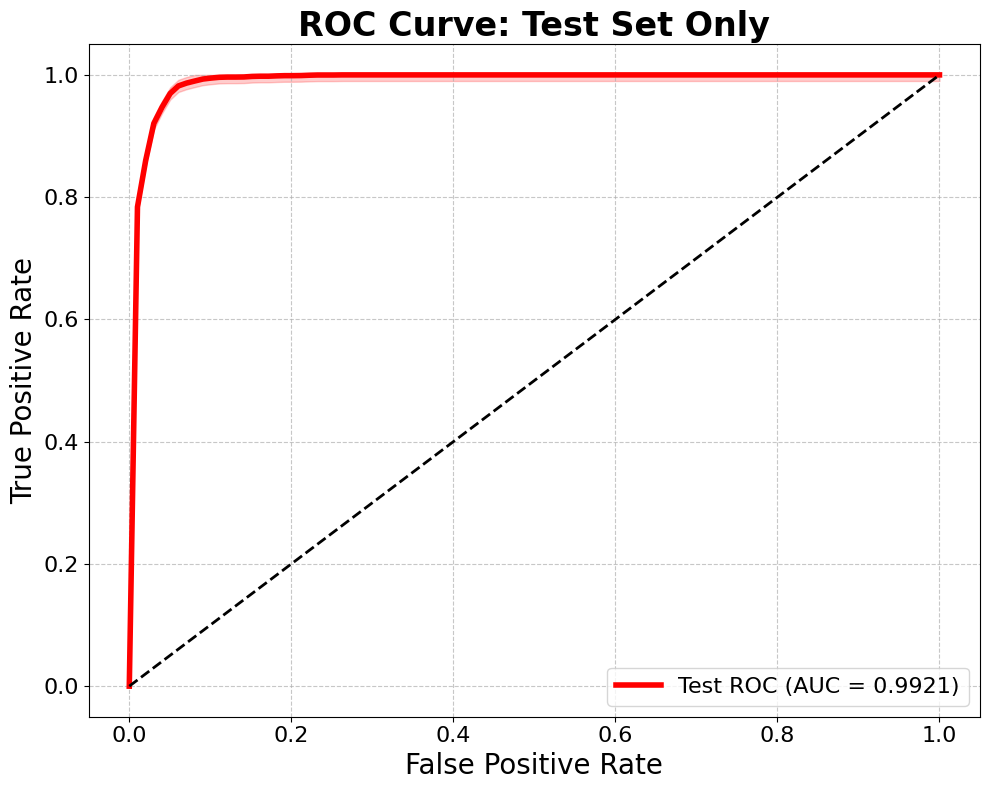


✅ Final stacking ensemble model saved as 'stacking_ensemble_knn_etc_lr.pkl'


In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import ExtraTreesClassifier, StackingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, classification_report,
                             confusion_matrix, roc_curve, auc)
import joblib
from collections import Counter

# === Assume X_train, y_train, X_test, y_test are defined ===

# Hyperparameter grids for base models
param_grid_knn = {
    'n_neighbors': [3, 5, 7],
    'weights': ['uniform', 'distance', 'uniform'],
    'algorithm': ['auto', 'ball_tree', 'kd_tree'],
    'leaf_size': [20, 30, 40],
    'p': [1, 2, 3]
}

param_grid_etc = {
    'n_estimators': [50, 100, 150],
    'max_depth': [6, 12, 18],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'bootstrap': [True, False]
}

param_grid_meta = {
    'C': [0.01, 0.1, 1],
    'penalty': ['l1', 'l2', 'elasticnet'],
    'solver': ['saga', 'liblinear', 'saga']
}

def tune_base_model(model, param_grid, X_tr, y_tr):
    rcv = RandomizedSearchCV(
        model,
        param_distributions=param_grid,
        n_iter=15,
        scoring='accuracy',
        cv=3,
        n_jobs=-1,
        random_state=42,
        verbose=0
    )
    rcv.fit(X_tr, y_tr)
    return rcv.best_estimator_, rcv.best_params_

skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

fold_metrics = []
fold_conf_matrices = []
tprs = []
roc_aucs = []
mean_fpr = np.linspace(0, 1, 100)

print("Starting 10-fold CV for stacking ensemble with KNN + ETC...\n")

for fold, (train_idx, val_idx) in enumerate(skf.split(X_train, y_train), 1):
    print(f"=== Fold {fold} ===")
    X_tr, X_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
    y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]

    print("Tuning KNN...")
    best_knn, best_knn_params = tune_base_model(KNeighborsClassifier(), param_grid_knn, X_tr, y_tr)
    print(f"KNN best params: {best_knn_params}")

    print("Tuning ExtraTrees...")
    best_etc, best_etc_params = tune_base_model(ExtraTreesClassifier(random_state=42), param_grid_etc, X_tr, y_tr)
    print(f"ETC best params: {best_etc_params}")

    base_estimators = [
        ('knn', best_knn),
        ('etc', best_etc)
    ]

    meta_lr = LogisticRegression(random_state=42, max_iter=1000)

    stacking_clf = StackingClassifier(
        estimators=base_estimators,
        final_estimator=meta_lr,
        cv=3,
        n_jobs=-1,
        passthrough=False,
        verbose=0
    )

    print("Tuning meta LogisticRegression inside stacking...")
    meta_rcv = RandomizedSearchCV(
        stacking_clf,
        param_distributions={
            'final_estimator__C': param_grid_meta['C'],
            'final_estimator__penalty': param_grid_meta['penalty'],
            'final_estimator__solver': param_grid_meta['solver'],
        },
        n_iter=15,
        scoring='accuracy',
        cv=3,
        n_jobs=-1,
        random_state=42,
        verbose=0
    )
    meta_rcv.fit(X_tr, y_tr)
    best_stacking = meta_rcv.best_estimator_

    print(f"Best meta params: {meta_rcv.best_params_}")

    y_pred = best_stacking.predict(X_val)
    y_prob = best_stacking.predict_proba(X_val)[:, 1]

    acc = accuracy_score(y_val, y_pred)
    pre = precision_score(y_val, y_pred, average='weighted', zero_division=0)
    rec = recall_score(y_val, y_pred, average='weighted', zero_division=0)
    f1 = f1_score(y_val, y_pred, average='weighted', zero_division=0)
    roc = roc_auc_score(y_val, y_prob)

    fold_metrics.append((acc, pre, rec, f1, roc))

    print(f"Accuracy:  {acc:.4f}")
    print(f"Precision: {pre:.4f}")
    print(f"Recall:    {rec:.4f}")
    print(f"F1-score:  {f1:.4f}")
    print(f"ROC AUC:   {roc:.4f}\n")

    cm = confusion_matrix(y_val, y_pred)
    fold_conf_matrices.append(cm)

    fpr, tpr, _ = roc_curve(y_val, y_prob)
    tprs.append(np.interp(mean_fpr, fpr, tpr))
    tprs[-1][0] = 0.0
    roc_aucs.append(roc)

metrics_array = np.array(fold_metrics)
metrics_names = ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC AUC']

print("=== Cross-validation Summary ===")
for i, metric_name in enumerate(metrics_names):
    mean_val = metrics_array[:, i].mean()
    std_val = metrics_array[:, i].std()
    print(f"{metric_name}: Mean = {mean_val:.4f}, Std = {std_val:.4f}")

sum_cm = np.sum(fold_conf_matrices, axis=0)

plt.figure(figsize=(8, 8))
sns.heatmap(sum_cm, annot=True, fmt='d', cmap='Greens', cbar=False,
            annot_kws={"size": 20})
plt.title('Aggregated Confusion Matrix (CV)', fontsize=24, fontweight='bold')
plt.xlabel('Predicted Label', fontsize=18)
plt.ylabel('True Label', fontsize=18)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.tight_layout()
plt.show()

mean_tpr = np.mean(tprs, axis=0)
mean_tpr[-1] = 1.0
mean_auc = auc(mean_fpr, mean_tpr)
std_auc = np.std(roc_aucs)

tprs_upper = np.minimum(mean_tpr + np.std(tprs, axis=0), 1)
tprs_lower = np.maximum(mean_tpr - np.std(tprs, axis=0), 0)

plt.figure(figsize=(10, 8))
plt.plot(mean_fpr, mean_tpr, color='blue', lw=4,
         label=f'Mean CV ROC (AUC = {mean_auc:.4f} ± {std_auc:.4f})')
plt.fill_between(mean_fpr, tprs_lower, tprs_upper, color='blue', alpha=0.2)
plt.plot([0, 1], [0, 1], 'k--', lw=2)

plt.xlabel('False Positive Rate', fontsize=20)
plt.ylabel('True Positive Rate', fontsize=20)
plt.title('Mean ROC Curve with ±1 Std Dev (CV)', fontsize=24, fontweight='bold')
plt.legend(loc='lower right', fontsize=16)
plt.grid(alpha=0.7, linestyle='--')
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.tight_layout()
plt.show()

# Final model training on full data

print("\nTraining final stacking model on full training data...")

final_knn, final_knn_params = tune_base_model(KNeighborsClassifier(), param_grid_knn, X_train, y_train)
final_etc, final_etc_params = tune_base_model(ExtraTreesClassifier(random_state=42), param_grid_etc, X_train, y_train)

print(f"Final KNN params: {final_knn_params}")
print(f"Final ETC params: {final_etc_params}")

base_estimators_final = [
    ('knn', final_knn),
    ('etc', final_etc)
]

stacking_final = StackingClassifier(
    estimators=base_estimators_final,
    final_estimator=LogisticRegression(random_state=42, max_iter=1000),
    cv=3,
    n_jobs=-1,
    passthrough=False,
    verbose=0
)

meta_rcv_final = RandomizedSearchCV(
    stacking_final,
    param_distributions={
        'final_estimator__C': param_grid_meta['C'],
        'final_estimator__penalty': param_grid_meta['penalty'],
        'final_estimator__solver': param_grid_meta['solver'],
    },
    n_iter=15,
    scoring='accuracy',
    cv=3,
    n_jobs=-1,
    random_state=42,
    verbose=0
)

meta_rcv_final.fit(X_train, y_train)
final_model = meta_rcv_final.best_estimator_

print(f"Final meta params: {meta_rcv_final.best_params_}")

# Test evaluation

y_test_pred = final_model.predict(X_test)
y_test_prob = final_model.predict_proba(X_test)[:, 1]

acc = accuracy_score(y_test, y_test_pred)
pre = precision_score(y_test, y_test_pred, average='weighted', zero_division=0)
rec = recall_score(y_test, y_test_pred, average='weighted', zero_division=0)
f1 = f1_score(y_test, y_test_pred, average='weighted', zero_division=0)
roc_auc = roc_auc_score(y_test, y_test_prob)

print("\n=== Test Set Performance ===")
print(classification_report(y_test, y_test_pred))
print(f"Accuracy:  {acc:.4f}")
print(f"Precision: {pre:.4f}")
print(f"Recall:    {rec:.4f}")
print(f"F1-score:  {f1:.4f}")
print(f"ROC AUC:   {roc_auc:.4f}")

cm_test = confusion_matrix(y_test, y_test_pred)
plt.figure(figsize=(8, 8))
sns.heatmap(cm_test, annot=True, fmt='d', cmap='Greens', cbar=False,
            annot_kws={"size": 20})
plt.title('Test Set Confusion Matrix', fontsize=24, fontweight='bold')
plt.xlabel('Predicted Label', fontsize=18)
plt.ylabel('True Label', fontsize=18)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 8))
plt.plot(mean_fpr, mean_tpr, color='blue', lw=4,
         label=f'Mean CV ROC (AUC = {mean_auc:.4f} ± {std_auc:.4f})')
plt.fill_between(mean_fpr, tprs_lower, tprs_upper, color='blue', alpha=0.2)

fpr_test, tpr_test, _ = roc_curve(y_test, y_test_prob)
plt.plot(fpr_test, tpr_test, color='red', lw=4,
         label=f'Test ROC (AUC = {roc_auc:.4f})')

plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlabel('False Positive Rate', fontsize=20)
plt.ylabel('True Positive Rate', fontsize=20)
plt.title('ROC Curve: CV vs Test', fontsize=24, fontweight='bold')
plt.legend(loc='lower right', fontsize=16)
plt.grid(alpha=0.7, linestyle='--')
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.tight_layout()
plt.show()

mean_fpr_test = np.linspace(0, 1, 100)
interp_tpr_test = np.interp(mean_fpr_test, fpr_test, tpr_test)
interp_tpr_test[0] = 0.0
interp_tpr_test[-1] = 1.0

plt.figure(figsize=(10, 8))
plt.plot(mean_fpr_test, interp_tpr_test, color='red', lw=4,
         label=f'Test ROC (AUC = {roc_auc:.4f})')

plt.fill_between(mean_fpr_test,
                 np.maximum(interp_tpr_test - 0.01, 0),
                 np.minimum(interp_tpr_test + 0.01, 1),
                 color='red', alpha=0.2)

plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlabel('False Positive Rate', fontsize=20)
plt.ylabel('True Positive Rate', fontsize=20)
plt.title('ROC Curve: Test Set Only', fontsize=24, fontweight='bold')
plt.legend(loc='lower right', fontsize=16)
plt.grid(alpha=0.7, linestyle='--')
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.tight_layout()
plt.show()

joblib.dump(final_model, 'stacking_ensemble_knn_etc_lr.pkl')
print("\n✅ Final stacking ensemble model saved as 'stacking_ensemble_knn_etc_lr.pkl'")


# **KNN and RF**

Starting 10-fold CV for stacking ensemble with KNN + RF...

=== Fold 1 ===
Tuning KNN...
KNN best params: {'weights': 'distance', 'p': 1, 'n_neighbors': 3, 'leaf_size': 20, 'algorithm': 'ball_tree'}
Tuning RandomForest...
RF best params: {'n_estimators': 50, 'min_samples_split': 2, 'min_samples_leaf': 2, 'max_depth': 18, 'bootstrap': False}
Tuning meta LogisticRegression inside stacking...
Best meta params: {'final_estimator__solver': 'saga', 'final_estimator__penalty': 'l2', 'final_estimator__C': 0.1}
Accuracy:  0.9685
Precision: 0.9688
Recall:    0.9685
F1-score:  0.9685
ROC AUC:   0.9955

=== Fold 2 ===
Tuning KNN...
KNN best params: {'weights': 'distance', 'p': 1, 'n_neighbors': 3, 'leaf_size': 20, 'algorithm': 'ball_tree'}
Tuning RandomForest...
RF best params: {'n_estimators': 50, 'min_samples_split': 2, 'min_samples_leaf': 2, 'max_depth': 18, 'bootstrap': False}
Tuning meta LogisticRegression inside stacking...
Best meta params: {'final_estimator__solver': 'saga', 'final_estimat

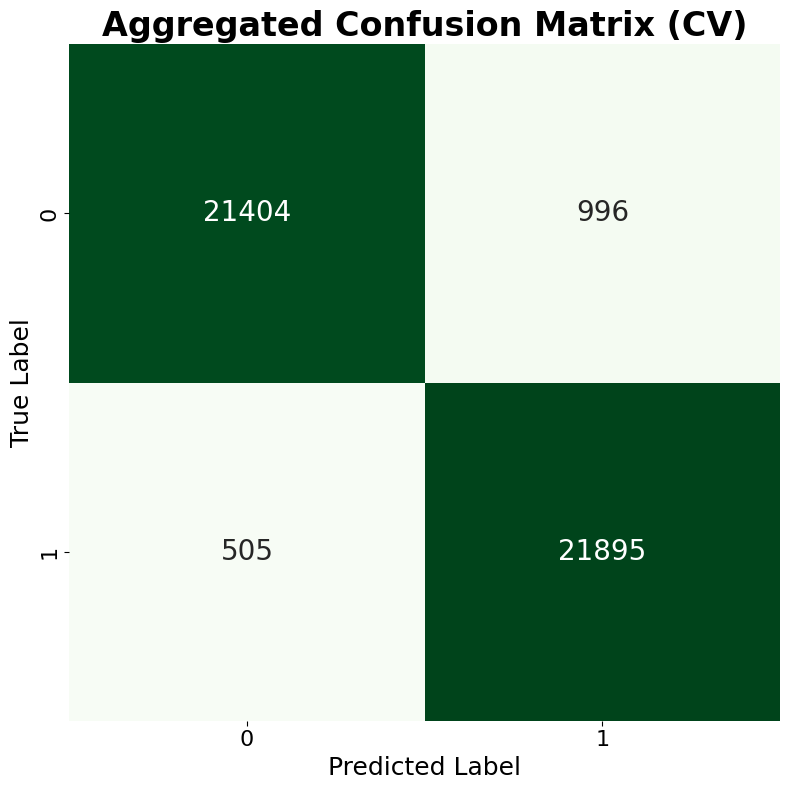

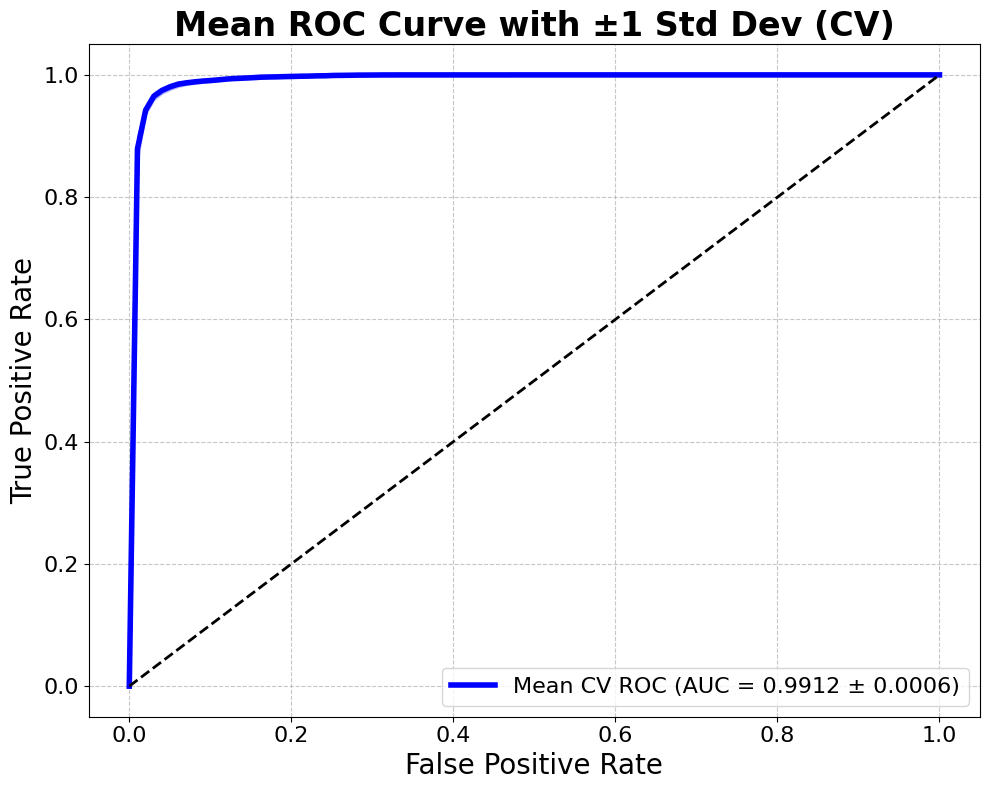


Training final stacking model on full training data...
Final KNN params: {'weights': 'distance', 'p': 1, 'n_neighbors': 3, 'leaf_size': 20, 'algorithm': 'ball_tree'}
Final RF params: {'n_estimators': 50, 'min_samples_split': 2, 'min_samples_leaf': 2, 'max_depth': 18, 'bootstrap': False}
Final meta params: {'final_estimator__solver': 'saga', 'final_estimator__penalty': 'l2', 'final_estimator__C': 0.1}

=== Test Set Performance ===
              precision    recall  f1-score   support

         0.0       0.99      0.96      0.97      5600
         1.0       0.96      0.99      0.97      5600

    accuracy                           0.97     11200
   macro avg       0.97      0.97      0.97     11200
weighted avg       0.97      0.97      0.97     11200

Accuracy:  0.9714
Precision: 0.9719
Recall:    0.9714
F1-score:  0.9714
ROC AUC:   0.9964


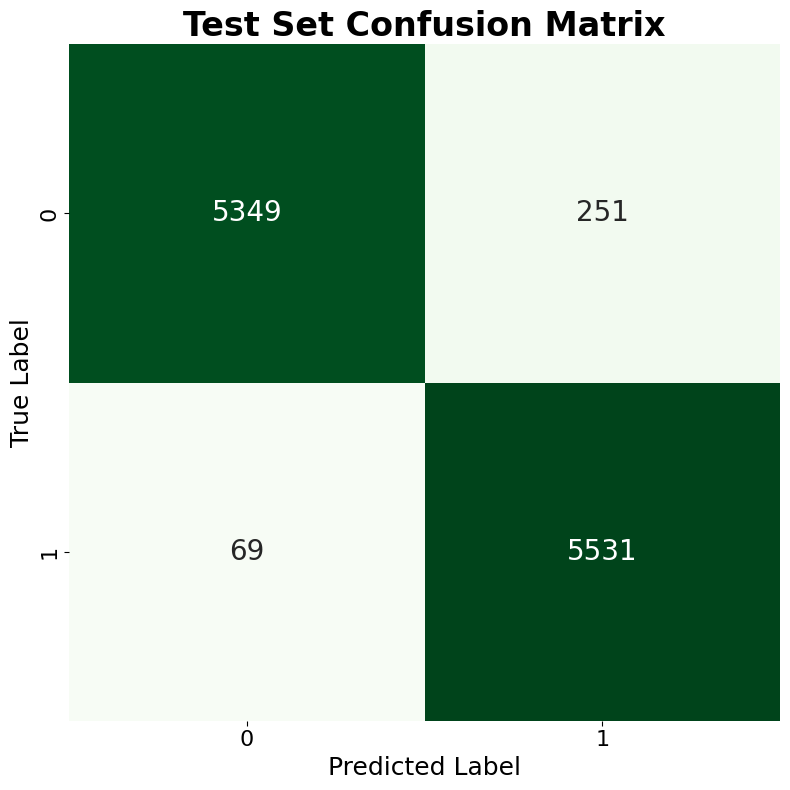

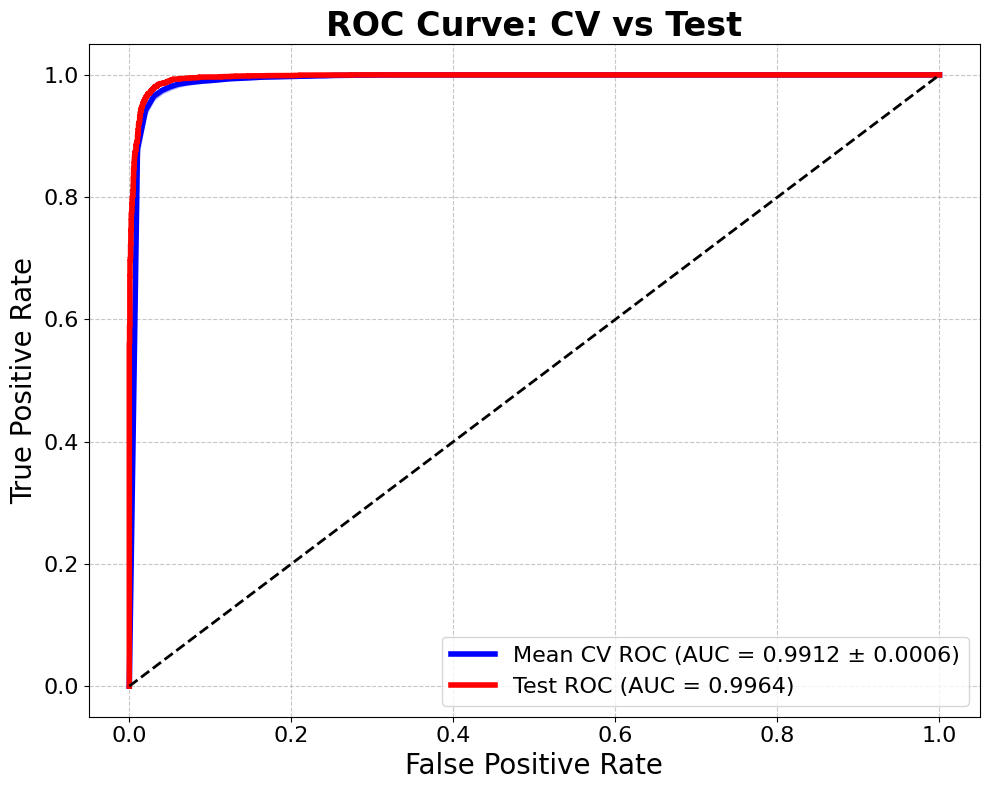

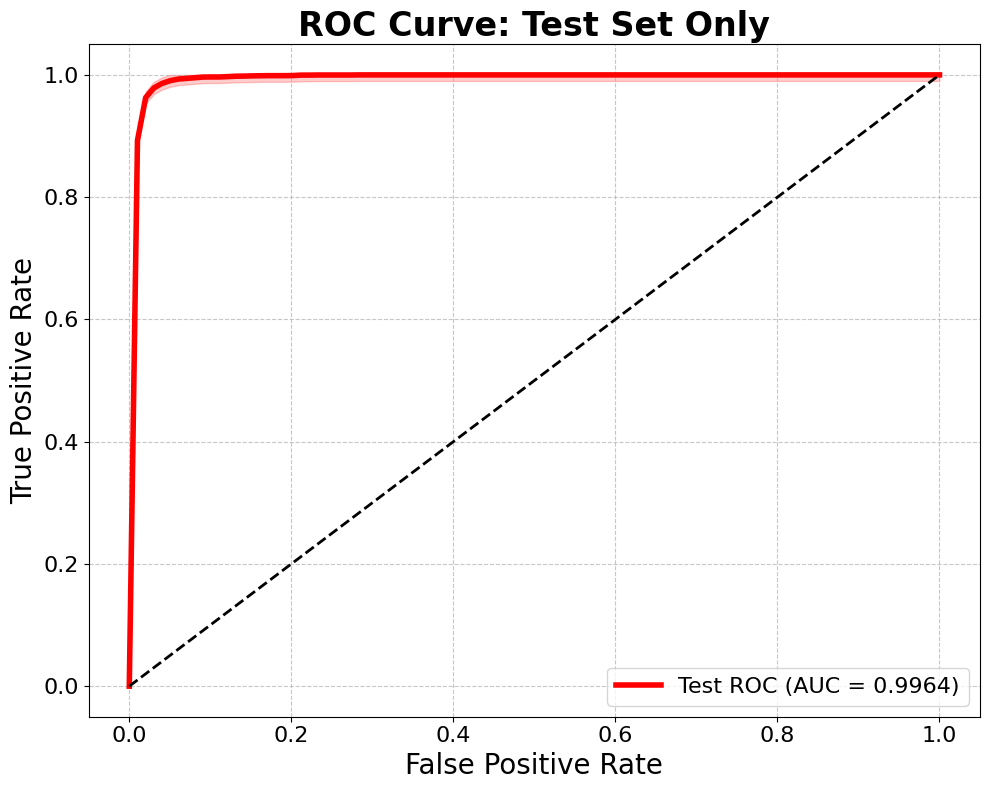


✅ Final stacking ensemble model saved as 'stacking_ensemble_knn_rf_lr.pkl'


In [29]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, classification_report,
                             confusion_matrix, roc_curve, auc)
import joblib
from collections import Counter

# === Assume X_train, y_train, X_test, y_test are defined ===

param_grid_knn = {
    'n_neighbors': [3, 5, 7],
    'weights': ['uniform', 'distance', 'uniform'],
    'algorithm': ['auto', 'ball_tree', 'kd_tree'],
    'leaf_size': [20, 30, 40],
    'p': [1, 2, 3]
}

param_grid_rf = {
    'n_estimators': [50, 100, 150],
    'max_depth': [6, 12, 18],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'bootstrap': [True, False]
}

param_grid_meta = {
    'C': [0.01, 0.1, 1],
    'penalty': ['l1', 'l2', 'elasticnet'],
    'solver': ['saga', 'liblinear', 'saga']
}

def tune_base_model(model, param_grid, X_tr, y_tr):
    rcv = RandomizedSearchCV(
        model,
        param_distributions=param_grid,
        n_iter=15,
        scoring='accuracy',
        cv=3,
        n_jobs=-1,
        random_state=42,
        verbose=0
    )
    rcv.fit(X_tr, y_tr)
    return rcv.best_estimator_, rcv.best_params_

skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

fold_metrics = []
fold_conf_matrices = []
tprs = []
roc_aucs = []
mean_fpr = np.linspace(0, 1, 100)

print("Starting 10-fold CV for stacking ensemble with KNN + RF...\n")

for fold, (train_idx, val_idx) in enumerate(skf.split(X_train, y_train), 1):
    print(f"=== Fold {fold} ===")
    X_tr, X_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
    y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]

    print("Tuning KNN...")
    best_knn, best_knn_params = tune_base_model(KNeighborsClassifier(), param_grid_knn, X_tr, y_tr)
    print(f"KNN best params: {best_knn_params}")

    print("Tuning RandomForest...")
    best_rf, best_rf_params = tune_base_model(RandomForestClassifier(random_state=42), param_grid_rf, X_tr, y_tr)
    print(f"RF best params: {best_rf_params}")

    base_estimators = [
        ('knn', best_knn),
        ('rf', best_rf)
    ]

    meta_lr = LogisticRegression(random_state=42, max_iter=1000)

    stacking_clf = StackingClassifier(
        estimators=base_estimators,
        final_estimator=meta_lr,
        cv=3,
        n_jobs=-1,
        passthrough=False,
        verbose=0
    )

    print("Tuning meta LogisticRegression inside stacking...")
    meta_rcv = RandomizedSearchCV(
        stacking_clf,
        param_distributions={
            'final_estimator__C': param_grid_meta['C'],
            'final_estimator__penalty': param_grid_meta['penalty'],
            'final_estimator__solver': param_grid_meta['solver'],
        },
        n_iter=15,
        scoring='accuracy',
        cv=3,
        n_jobs=-1,
        random_state=42,
        verbose=0
    )
    meta_rcv.fit(X_tr, y_tr)
    best_stacking = meta_rcv.best_estimator_

    print(f"Best meta params: {meta_rcv.best_params_}")

    y_pred = best_stacking.predict(X_val)
    y_prob = best_stacking.predict_proba(X_val)[:, 1]

    acc = accuracy_score(y_val, y_pred)
    pre = precision_score(y_val, y_pred, average='weighted', zero_division=0)
    rec = recall_score(y_val, y_pred, average='weighted', zero_division=0)
    f1 = f1_score(y_val, y_pred, average='weighted', zero_division=0)
    roc = roc_auc_score(y_val, y_prob)

    fold_metrics.append((acc, pre, rec, f1, roc))

    print(f"Accuracy:  {acc:.4f}")
    print(f"Precision: {pre:.4f}")
    print(f"Recall:    {rec:.4f}")
    print(f"F1-score:  {f1:.4f}")
    print(f"ROC AUC:   {roc:.4f}\n")

    cm = confusion_matrix(y_val, y_pred)
    fold_conf_matrices.append(cm)

    fpr, tpr, _ = roc_curve(y_val, y_prob)
    tprs.append(np.interp(mean_fpr, fpr, tpr))
    tprs[-1][0] = 0.0
    roc_aucs.append(roc)

metrics_array = np.array(fold_metrics)
metrics_names = ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC AUC']

print("=== Cross-validation Summary ===")
for i, metric_name in enumerate(metrics_names):
    mean_val = metrics_array[:, i].mean()
    std_val = metrics_array[:, i].std()
    print(f"{metric_name}: Mean = {mean_val:.4f}, Std = {std_val:.4f}")

sum_cm = np.sum(fold_conf_matrices, axis=0)

plt.figure(figsize=(8, 8))
sns.heatmap(sum_cm, annot=True, fmt='d', cmap='Greens', cbar=False,
            annot_kws={"size": 20})
plt.title('Aggregated Confusion Matrix (CV)', fontsize=24, fontweight='bold')
plt.xlabel('Predicted Label', fontsize=18)
plt.ylabel('True Label', fontsize=18)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.tight_layout()
plt.show()

mean_tpr = np.mean(tprs, axis=0)
mean_tpr[-1] = 1.0
mean_auc = auc(mean_fpr, mean_tpr)
std_auc = np.std(roc_aucs)

tprs_upper = np.minimum(mean_tpr + np.std(tprs, axis=0), 1)
tprs_lower = np.maximum(mean_tpr - np.std(tprs, axis=0), 0)

plt.figure(figsize=(10, 8))
plt.plot(mean_fpr, mean_tpr, color='blue', lw=4,
         label=f'Mean CV ROC (AUC = {mean_auc:.4f} ± {std_auc:.4f})')
plt.fill_between(mean_fpr, tprs_lower, tprs_upper, color='blue', alpha=0.2)
plt.plot([0, 1], [0, 1], 'k--', lw=2)

plt.xlabel('False Positive Rate', fontsize=20)
plt.ylabel('True Positive Rate', fontsize=20)
plt.title('Mean ROC Curve with ±1 Std Dev (CV)', fontsize=24, fontweight='bold')
plt.legend(loc='lower right', fontsize=16)
plt.grid(alpha=0.7, linestyle='--')
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.tight_layout()
plt.show()

# Final model training on full data

print("\nTraining final stacking model on full training data...")

final_knn, final_knn_params = tune_base_model(KNeighborsClassifier(), param_grid_knn, X_train, y_train)
final_rf, final_rf_params = tune_base_model(RandomForestClassifier(random_state=42), param_grid_rf, X_train, y_train)

print(f"Final KNN params: {final_knn_params}")
print(f"Final RF params: {final_rf_params}")

base_estimators_final = [
    ('knn', final_knn),
    ('rf', final_rf)
]

stacking_final = StackingClassifier(
    estimators=base_estimators_final,
    final_estimator=LogisticRegression(random_state=42, max_iter=1000),
    cv=3,
    n_jobs=-1,
    passthrough=False,
    verbose=0
)

meta_rcv_final = RandomizedSearchCV(
    stacking_final,
    param_distributions={
        'final_estimator__C': param_grid_meta['C'],
        'final_estimator__penalty': param_grid_meta['penalty'],
        'final_estimator__solver': param_grid_meta['solver'],
    },
    n_iter=15,
    scoring='accuracy',
    cv=3,
    n_jobs=-1,
    random_state=42,
    verbose=0
)

meta_rcv_final.fit(X_train, y_train)
final_model = meta_rcv_final.best_estimator_

print(f"Final meta params: {meta_rcv_final.best_params_}")

# Test evaluation

y_test_pred = final_model.predict(X_test)
y_test_prob = final_model.predict_proba(X_test)[:, 1]

acc = accuracy_score(y_test, y_test_pred)
pre = precision_score(y_test, y_test_pred, average='weighted', zero_division=0)
rec = recall_score(y_test, y_test_pred, average='weighted', zero_division=0)
f1 = f1_score(y_test, y_test_pred, average='weighted', zero_division=0)
roc_auc = roc_auc_score(y_test, y_test_prob)

print("\n=== Test Set Performance ===")
print(classification_report(y_test, y_test_pred))
print(f"Accuracy:  {acc:.4f}")
print(f"Precision: {pre:.4f}")
print(f"Recall:    {rec:.4f}")
print(f"F1-score:  {f1:.4f}")
print(f"ROC AUC:   {roc_auc:.4f}")

cm_test = confusion_matrix(y_test, y_test_pred)
plt.figure(figsize=(8, 8))
sns.heatmap(cm_test, annot=True, fmt='d', cmap='Greens', cbar=False,
            annot_kws={"size": 20})
plt.title('Test Set Confusion Matrix', fontsize=24, fontweight='bold')
plt.xlabel('Predicted Label', fontsize=18)
plt.ylabel('True Label', fontsize=18)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 8))
plt.plot(mean_fpr, mean_tpr, color='blue', lw=4,
         label=f'Mean CV ROC (AUC = {mean_auc:.4f} ± {std_auc:.4f})')
plt.fill_between(mean_fpr, tprs_lower, tprs_upper, color='blue', alpha=0.2)

fpr_test, tpr_test, _ = roc_curve(y_test, y_test_prob)
plt.plot(fpr_test, tpr_test, color='red', lw=4,
         label=f'Test ROC (AUC = {roc_auc:.4f})')

plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlabel('False Positive Rate', fontsize=20)
plt.ylabel('True Positive Rate', fontsize=20)
plt.title('ROC Curve: CV vs Test', fontsize=24, fontweight='bold')
plt.legend(loc='lower right', fontsize=16)
plt.grid(alpha=0.7, linestyle='--')
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.tight_layout()
plt.show()

mean_fpr_test = np.linspace(0, 1, 100)
interp_tpr_test = np.interp(mean_fpr_test, fpr_test, tpr_test)
interp_tpr_test[0] = 0.0
interp_tpr_test[-1] = 1.0

plt.figure(figsize=(10, 8))
plt.plot(mean_fpr_test, interp_tpr_test, color='red', lw=4,
         label=f'Test ROC (AUC = {roc_auc:.4f})')

plt.fill_between(mean_fpr_test,
                 np.maximum(interp_tpr_test - 0.01, 0),
                 np.minimum(interp_tpr_test + 0.01, 1),
                 color='red', alpha=0.2)

plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlabel('False Positive Rate', fontsize=20)
plt.ylabel('True Positive Rate', fontsize=20)
plt.title('ROC Curve: Test Set Only', fontsize=24, fontweight='bold')
plt.legend(loc='lower right', fontsize=16)
plt.grid(alpha=0.7, linestyle='--')
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.tight_layout()
plt.show()

joblib.dump(final_model, 'stacking_ensemble_knn_rf_lr.pkl')
print("\n✅ Final stacking ensemble model saved as 'stacking_ensemble_knn_rf_lr.pkl'")
